# Meta-características para regressão desbalanceada

Atividade prática 2 de IN1097, Carlos Henrique Dias.

Neste notebook calculamos medidas de complexidade em três grupos de cada dataset (todos os exemplos, só os normais e só os raros, separados pela relevância φ(y)) e testamos se elas melhoram a recomendação de regressores da Atividade 1.

No repositório, usamos os 30 CSVs de `../data/` e as matrizes de `../meta-dataset/`. Fora dele, a estrutura original usa `dados/` e `entradas/`. Arquivos de entrada: o `X.csv`, o `P_resampling.csv`, o `R_resampling.csv` e o `resultados_por_fold_resampling.csv` da Atividade 1, o código da Atividade 1 (`abordagens_meta_modelo.py`, `abordagens_agregacao.py` e `harris.py`) e a primeira versão do avaliador (`avaliar_colab.py`).

Obs.: depois da execução, organizamos os textos, trouxemos as funções de avaliação para dentro do notebook e trocamos os uploads de arquivos pela leitura da pasta `entradas/`. As saídas são as da execução original.

## 1. Preparação do ambiente

Criamos as pastas de dados, resultados e figuras e fixamos a semente (42) e o limiar de relevância (0,8), que separa normais de raros. Os arquivos que vêm da Atividade 1 ficam na pasta `entradas/`.

In [ ]:
from pathlib import Path

SEED = 42
LIMIAR_RELEVANCIA = 0.8

# No repositório, reutilizamos os dados e as matrizes compartilhadas.
# Fora dele (por exemplo no Colab), mantemos as pastas locais originais.
candidatos = [Path.cwd(), Path.cwd().parent, Path.cwd() / "projeto-01"]
BASE = next((p.resolve() for p in candidatos if (p / "meta-dataset").is_dir() and (p / "data").is_dir()), None)
PASTA_DADOS = BASE / "data" if BASE else Path("dados")
PASTA_RESULTADOS = BASE / "pratica-02" / "resultados" if BASE else Path("resultados")
PASTA_FIGURAS = BASE / "pratica-02" / "figuras" if BASE else Path("figuras")

for pasta in (PASTA_DADOS, PASTA_RESULTADOS, PASTA_FIGURAS):
    pasta.mkdir(parents=True, exist_ok=True)

print("Pastas preparadas:")
for pasta in (PASTA_DADOS, PASTA_RESULTADOS, PASTA_FIGURAS):
    print(f"  {pasta}/")

print(f"\nSemente: {SEED}")
print(f"Limiar de relevância: {LIMIAR_RELEVANCIA}")

In [ ]:
import sys

# Arquivos da Atividade 1 e primeira versão do avaliador, enviados pelo painel de arquivos do Colab.
PASTA_ENTRADAS = BASE / "meta-dataset" if BASE else Path("entradas")
sys.path.append(str(BASE / "codigo" if BASE else PASTA_ENTRADAS))

## 2. Datasets

Usamos os 30 datasets do repositório JusciAvelino/imbalancedRegression, enviados para a pasta `dados/`. A primeira coluna de cada arquivo é o alvo. Antes de tudo, conferimos se há valores ausentes, infinitos ou colunas não numéricas.

In [3]:
import numpy as np
import pandas as pd

arquivos_csv = sorted(PASTA_DADOS.glob("*.csv"))

if not arquivos_csv:
    raise FileNotFoundError("Nenhum CSV encontrado na pasta dados.")

datasets = {}
registros = []

for arquivo in arquivos_csv:
    df = pd.read_csv(arquivo)
    datasets[arquivo.stem] = df

    numericas = df.select_dtypes(include="number")

    registros.append({
        "dataset": arquivo.stem,
        "n_exemplos": df.shape[0],
        "n_preditores": df.shape[1] - 1,
        "coluna_alvo": df.columns[0],
        "valores_distintos_alvo": df.iloc[:, 0].nunique(),
        "ausentes": int(df.isna().sum().sum()),
        "infinitos": int(np.isinf(numericas.to_numpy()).sum()),
        "colunas_nao_numericas": df.select_dtypes(
            exclude="number"
        ).shape[1],
    })

inventario = pd.DataFrame(registros).sort_values("dataset")

PASTA_RESULTADOS.mkdir(parents=True, exist_ok=True)
inventario.to_csv(
    PASTA_RESULTADOS / "inventario_datasets.csv",
    index=False,
)

display(inventario)

print(f"\nDatasets carregados: {len(datasets)}")
print("Datasets com ausentes:", int((inventario["ausentes"] > 0).sum()))
print("Datasets com infinitos:", int((inventario["infinitos"] > 0).sum()))
print(
    "Datasets com colunas não numéricas:",
    int((inventario["colunas_nao_numericas"] > 0).sum()),
)

,dataset,n_exemplos,n_preditores,coluna_alvo,valores_distintos_alvo,ausentes,infinitos,colunas_nao_numericas
0,a1,198,11,a1,120,0,0,0
1,a2,198,11,a2,88,0,0,0
2,a3,198,11,a3,79,0,0,0
3,a7,198,11,a7,50,0,0,0
4,abalone,4177,8,Rings,28,0,0,0
5,acceleration,1732,14,target,164,0,0,0
6,airfoild,1503,5,target,1456,0,0,0
7,analcatdata_apnea3,450,11,target,159,0,0,0
8,available_power,1802,15,target,164,0,0,0
9,boston,506,13,target,229,0,0,0



Datasets carregados: 30
Datasets com ausentes: 0
Datasets com infinitos: 0
Datasets com colunas não numéricas: 0


## 3. Relevância e grupos

A relevância φ(y) é calculada com o smogn (método automático, as duas caudas, coeficiente 1,5) sobre o alvo original. Raros são os exemplos com φ(y) ≥ 0,8; normais, os demais.

In [4]:
%pip install -q smogn==0.1.2

In [8]:
from smogn.phi_ctrl_pts import phi_ctrl_pts
from smogn.phi import phi

def calcular_relevancia(y):
    y = pd.Series(y, dtype=float).reset_index(drop=True)

    if y.nunique() < 2:
        raise ValueError("O alvo é constante; precisamos tratar esse caso.")

    parametros = phi_ctrl_pts(
        y=y,
        method="auto",
        xtrm_type="both",
        coef=1.5,
    )

    relevancia = np.asarray(
        phi(y=y, ctrl_pts=parametros),
        dtype=float,
    )

    if not np.isfinite(relevancia).all():
        raise ValueError("A função de relevância produziu valores inválidos.")

    if np.any((relevancia < 0) | (relevancia > 1)):
        raise ValueError("Há valores de relevância fora de [0, 1].")

    return relevancia, parametros

In [9]:
relevancias = {}
parametros_relevancia = {}
grupos = {}
registros_grupos = []

for nome, df in datasets.items():
    y = df.iloc[:, 0]

    relevancia, parametros = calcular_relevancia(y)

    mascara_raros = relevancia >= LIMIAR_RELEVANCIA
    mascara_normais = ~mascara_raros

    relevancias[nome] = relevancia
    parametros_relevancia[nome] = parametros

    grupos[nome] = {
        "todos": np.ones(len(df), dtype=bool),
        "normais": mascara_normais,
        "raros": mascara_raros,
    }

    registros_grupos.append({
        "dataset": nome,
        "n_total": len(df),
        "n_normais": int(mascara_normais.sum()),
        "n_raros": int(mascara_raros.sum()),
        "percentual_raros": 100 * mascara_raros.mean(),
    })

resumo_grupos = (
    pd.DataFrame(registros_grupos)
    .sort_values("percentual_raros", ascending=False)
)

resumo_grupos.to_csv(
    PASTA_RESULTADOS / "resumo_grupos.csv",
    index=False,
)

display(resumo_grupos.round(2))

print(
    "\nDatasets sem exemplos raros:",
    int((resumo_grupos["n_raros"] == 0).sum()),
)
print(
    "Datasets com menos de 10 exemplos raros:",
    int((resumo_grupos["n_raros"] < 10).sum()),
)

,dataset,n_total,n_normais,n_raros,percentual_raros
29,wine_quality,6497,4974,1523,23.44
7,analcatdata_apnea3,450,347,103,22.89
22,meta,528,420,108,20.45
9,boston,506,415,91,17.98
11,cocomo_numeric,60,50,10,16.67
4,abalone,4177,3498,679,16.26
2,a3,198,166,32,16.16
16,forestFires,517,438,79,15.28
0,a1,198,170,28,14.14
3,a7,198,171,27,13.64



Datasets sem exemplos raros: 0
Datasets com menos de 10 exemplos raros: 0


## 4. Meta-características de referência

Recalculamos as 13 meta-características da Atividade 1: tamanho, estatísticas dos preditores e do alvo e proporções de raros. Preditores constantes ficam de fora das médias de assimetria e curtose.

In [12]:
from scipy.stats import skew, kurtosis

def extrair_caracteristicas_base(nome, df):
    y = df.iloc[:, 0].to_numpy(dtype=float)
    Z = df.iloc[:, 1:]

    n, p = Z.shape
    raros = grupos[nome]["raros"]
    mediana = np.median(y)

    Z_variavel = Z.loc[:, Z.nunique() > 1]
    valores = Z_variavel.to_numpy(dtype=float)

    if Z_variavel.shape[1] > 0:
        assimetria_media = skew(
            valores, axis=0, bias=True
        ).mean()

        curtose_media = kurtosis(
            valores, axis=0, fisher=True, bias=True
        ).mean()
    else:
        assimetria_media = np.nan
        curtose_media = np.nan

    media_y = y.mean()

    return {
        "dataset": nome,
        "n_instances": n,
        "n_features": p,
        "instances_per_feature": n / p,
        "mean_of_means": Z.mean().mean(),
        "mean_of_stds": Z.std(ddof=1).mean(),
        "mean_skewness": assimetria_media,
        "mean_kurtosis": curtose_media,
        "y_skewness": skew(y, bias=True),
        "y_kurtosis": kurtosis(y, fisher=True, bias=True),
        "y_coef_variacao": (
            y.std(ddof=0) / media_y
            if media_y != 0 else np.nan
        ),
        "pct_relevante": raros.mean(),
        "pct_relevante_alta": (raros & (y > mediana)).mean(),
        "pct_relevante_baixa": (raros & (y < mediana)).mean(),
    }

In [13]:
registros_base = [
    extrair_caracteristicas_base(nome, df)
    for nome, df in datasets.items()
]

X_base = (
    pd.DataFrame(registros_base)
    .set_index("dataset")
    .sort_index()
)

X_base.to_csv(PASTA_RESULTADOS / "X_base.csv")

display(X_base.head().round(4))

print("Dimensão de X_base:", X_base.shape)
print(
    "Valores ausentes ou infinitos:",
    int((~np.isfinite(X_base.to_numpy())).sum()),
)

,n_instances,n_features,instances_per_feature,mean_of_means,mean_of_stds,mean_skewness,mean_kurtosis,y_skewness,y_kurtosis,y_coef_variacao,pct_relevante,pct_relevante_alta,pct_relevante_baixa
dataset,,,,,,,,,,,,,
a1,198,11,18.000,6729.0795,16904.2819,3.2206,27.7459,1.4626,1.3180,1.2572,0.1414,0.1414,0.0000
a2,198,11,18.000,6729.0795,16904.2819,3.2206,27.7459,2.4110,7.5883,1.4774,0.1111,0.1111,0.0000
a3,198,11,18.000,6729.0795,16904.2819,3.2206,27.7459,2.4672,6.9164,1.6056,0.1616,0.1616,0.0000
a7,198,11,18.000,6729.0795,16904.2819,3.2206,27.7459,3.7244,15.3674,2.0779,0.1364,0.1364,0.0000
abalone,4177,8,522.125,155.8578,199.8757,0.8043,-0.2756,1.1137,2.3265,0.3245,0.1626,0.1173,0.0452


Dimensão de X_base: (30, 13)
Valores ausentes ou infinitos: 0


## 5. Normalização

Preditores e alvo são normalizados por mínimo e máximo no dataset inteiro, antes de separar os grupos, para que todos fiquem na mesma escala.

In [14]:
def normalizar_minmax(valores):
    valores = np.asarray(valores, dtype=float)

    minimo = valores.min(axis=0)
    amplitude = valores.max(axis=0) - minimo

    # Evita divisão por zero em colunas constantes.
    divisor = np.where(amplitude > 0, amplitude, 1.0)

    return (valores - minimo) / divisor


dados_preparados = {}

for nome, df in datasets.items():
    Z_original = df.iloc[:, 1:].to_numpy(dtype=float)
    y_original = df.iloc[:, 0].to_numpy(dtype=float)

    dados_preparados[nome] = {
        "Z": normalizar_minmax(Z_original),
        "y": normalizar_minmax(y_original),
        "mascaras": grupos[nome],
    }

print(f"Datasets preparados: {len(dados_preparados)}")

Datasets preparados: 30


In [16]:
registros_tamanhos = []

for nome, dados in dados_preparados.items():
    p = dados["Z"].shape[1]

    for grupo, mascara in dados["mascaras"].items():
        n = int(mascara.sum())

        registros_tamanhos.append({
            "dataset": nome,
            "grupo": grupo,
            "n_exemplos": n,
            "n_preditores": p,
            "exemplos_por_preditor": n / p,
            "n_menor_ou_igual_p": n <= p,
        })

tamanhos_grupos = pd.DataFrame(registros_tamanhos)

tamanhos_grupos.to_csv(
    PASTA_RESULTADOS / "tamanhos_grupos.csv",
    index=False,
)

print("Quantidade de combinações dataset × grupo:", len(tamanhos_grupos))

print("\nGrupos com número de exemplos menor ou igual ao de preditores:")
display(
    tamanhos_grupos.loc[tamanhos_grupos["n_menor_ou_igual_p"]]
)

Quantidade de combinações dataset × grupo: 90

Grupos com número de exemplos menor ou igual ao de preditores:


,dataset,grupo,n_exemplos,n_preditores,exemplos_por_preditor,n_menor_ou_igual_p
34,cocomo_numeric,normais,50,56,0.892857,True
35,cocomo_numeric,raros,10,56,0.178571,True
72,pdgfr,todos,79,320,0.246875,True
73,pdgfr,normais,69,320,0.215625,True
74,pdgfr,raros,10,320,0.031250,True
86,triazines,raros,20,60,0.333333,True


## 6. C1 e C2

Correlação de Spearman (em módulo) de cada preditor com o alvo: C1 é a maior e C2 a média. Preditores constantes no grupo são ignorados.

In [17]:
from scipy.stats import spearmanr
from time import perf_counter

def calcular_c1_c2(Z, y):
    resultado = {
        "C1": np.nan,
        "C2": np.nan,
        "preditores_validos_C1_C2": 0,
        "status_C1_C2": "ok",
    }

    if len(y) < 2:
        resultado["status_C1_C2"] = "grupo_insuficiente"
        return resultado

    variaveis = np.ptp(Z, axis=0) > 0
    resultado["preditores_validos_C1_C2"] = int(variaveis.sum())

    if np.ptp(y) == 0:
        resultado["status_C1_C2"] = "alvo_constante"
        return resultado

    if not variaveis.any():
        resultado["status_C1_C2"] = "sem_preditor_variavel"
        return resultado

    correlacoes = np.array([
        abs(spearmanr(Z[:, j], y).statistic)
        for j in np.flatnonzero(variaveis)
    ])

    resultado["C1"] = float(correlacoes.max())
    resultado["C2"] = float(correlacoes.mean())

    return resultado

In [24]:
registros_correlacao = []

for nome, dados in dados_preparados.items():
    for grupo, mascara in dados["mascaras"].items():
        inicio = perf_counter()

        resultado = calcular_c1_c2(
            dados["Z"][mascara],
            dados["y"][mascara],
        )

        tempo = perf_counter() - inicio

        registros_correlacao.append({
            "dataset": nome,
            "grupo": grupo,
            **resultado,
            "tempo_C1_C2_s": tempo,
        })

complexidade_C1_C2 = pd.DataFrame(registros_correlacao)

complexidade_C1_C2.to_csv(
    PASTA_RESULTADOS / "complexidade_C1_C2.csv",
    index=False,
)

display(
    complexidade_C1_C2[
        complexidade_C1_C2["dataset"].isin(["boston", "pdgfr"])
    ].round(4)
)

print("\nCombinações calculadas:", len(complexidade_C1_C2))
print("\nSituação dos cálculos:")
print(complexidade_C1_C2["status_C1_C2"].value_counts())

print(
    "\nTempo total de C1 e C2:",
    round(complexidade_C1_C2["tempo_C1_C2_s"].sum(), 2),
    "segundos",
)

,dataset,grupo,C1,C2,preditores_validos_C1_C2,status_C1_C2,tempo_C1_C2_s
27,boston,todos,0.8529,0.4520,13,ok,0.0159
28,boston,normais,0.7764,0.4102,13,ok,0.0155
29,boston,raros,0.7320,0.3164,13,ok,0.0119
72,pdgfr,todos,0.6209,0.2762,304,ok,0.2211
73,pdgfr,normais,0.6883,0.2591,302,ok,0.2022
74,pdgfr,raros,0.8788,0.4827,282,ok,0.2523



Combinações calculadas: 90

Situação dos cálculos:
status_C1_C2
ok    90
Name: count, dtype: int64

Tempo total de C1 e C2: 2.26 segundos


## 7. L1 e L2

Erro absoluto (L1) e quadrático (L2) de uma regressão linear ajustada no grupo. Guardamos também o posto da matriz, para identificar ajustes saturados, em que o erro sai perto de zero sem que o grupo seja fácil.

In [19]:
from sklearn.linear_model import LinearRegression

def calcular_l1_l2(Z, y):
    variaveis = np.ptp(Z, axis=0) > 0
    Z_util = Z[:, variaveis]

    if Z_util.shape[1] == 0:
        # Modelo contendo somente o intercepto.
        predicoes = np.full(len(y), y.mean())
        posto = 0
    else:
        modelo = LinearRegression(fit_intercept=True)
        modelo.fit(Z_util, y)

        predicoes = modelo.predict(Z_util)
        posto = int(modelo.rank_)

    residuos = y - predicoes

    # O intercepto consome um grau de liberdade.
    graus_liberdade = len(y) - posto - 1

    return {
        "L1": float(np.mean(np.abs(residuos))),
        "L2": float(np.mean(residuos ** 2)),
        "preditores_validos_L1_L2": int(variaveis.sum()),
        "posto_linear": posto,
        "graus_liberdade_residuais": graus_liberdade,
        "ajuste_saturado": graus_liberdade <= 0,
    }

In [21]:
registros_linearidade = []

for nome, dados in dados_preparados.items():
    for grupo, mascara in dados["mascaras"].items():
        inicio = perf_counter()

        resultado = calcular_l1_l2(
            dados["Z"][mascara],
            dados["y"][mascara],
        )

        tempo = perf_counter() - inicio

        registros_linearidade.append({
            "dataset": nome,
            "grupo": grupo,
            **resultado,
            "tempo_L1_L2_s": tempo,
        })

complexidade_L1_L2 = pd.DataFrame(registros_linearidade)

complexidade_L1_L2.to_csv(
    PASTA_RESULTADOS / "complexidade_L1_L2.csv",
    index=False,
)

display(
    complexidade_L1_L2[
        complexidade_L1_L2["dataset"].isin(
            ["boston", "cocomo_numeric", "pdgfr"]
        )
    ].round(6)
)

print("\nCombinações calculadas:", len(complexidade_L1_L2))
print(
    "Ajustes saturados:",
    int(complexidade_L1_L2["ajuste_saturado"].sum()),
)
print(
    "Tempo total de L1 e L2:",
    round(complexidade_L1_L2["tempo_L1_L2_s"].sum(), 2),
    "segundos",
)

,dataset,grupo,L1,L2,preditores_validos_L1_L2,posto_linear,graus_liberdade_residuais,ajuste_saturado,tempo_L1_L2_s
27,boston,todos,0.086075,0.014316,13,13,492,False,0.004104
28,boston,normais,0.050961,0.004349,13,13,401,False,0.004015
29,boston,raros,0.104597,0.016658,13,13,77,False,0.003833
33,cocomo_numeric,todos,0.013337,0.000693,56,31,28,False,0.006509
34,cocomo_numeric,normais,0.003774,0.000052,52,24,25,False,0.004292
35,cocomo_numeric,raros,0.000000,0.000000,50,9,0,True,0.003702
72,pdgfr,todos,0.000000,0.000000,304,78,0,True,0.200312
73,pdgfr,normais,0.000000,0.000000,302,68,0,True,0.207192
74,pdgfr,raros,0.000000,0.000000,282,9,0,True,0.008274



Combinações calculadas: 90
Ajustes saturados: 4
Tempo total de L1 e L2: 1.38 segundos


## 8. L3

Geramos um ponto entre cada par de exemplos vizinhos na ordem do alvo (semente 42) e medimos o erro da regressão linear nesses pontos.

In [22]:
def gerar_pontos_interpolados(Z, y, seed):
    ordem = np.argsort(y, kind="stable")
    Z_ordenado = Z[ordem]
    y_ordenado = y[ordem]

    rng = np.random.default_rng(seed)
    pesos = rng.uniform(size=len(y) - 1)

    Z_interpolado = (
        pesos[:, None] * Z_ordenado[:-1]
        + (1 - pesos[:, None]) * Z_ordenado[1:]
    )

    y_interpolado = (
        pesos * y_ordenado[:-1]
        + (1 - pesos) * y_ordenado[1:]
    )

    return Z_interpolado, y_interpolado


def calcular_l3(Z, y):
    Z_interpolado, y_interpolado = gerar_pontos_interpolados(
        Z, y, seed=SEED
    )

    variaveis = np.ptp(Z, axis=0) > 0

    if not variaveis.any():
        predicoes = np.full(len(y_interpolado), y.mean())
    else:
        modelo = LinearRegression(fit_intercept=True)
        modelo.fit(Z[:, variaveis], y)

        predicoes = modelo.predict(
            Z_interpolado[:, variaveis]
        )

    return {
        "L3": float(np.mean((y_interpolado - predicoes) ** 2)),
        "n_interpolados": len(y_interpolado),
    }

In [23]:
registros_l3 = []

for nome, dados in dados_preparados.items():
    for grupo, mascara in dados["mascaras"].items():
        inicio = perf_counter()

        resultado = calcular_l3(
            dados["Z"][mascara],
            dados["y"][mascara],
        )

        registros_l3.append({
            "dataset": nome,
            "grupo": grupo,
            **resultado,
            "tempo_L3_s": perf_counter() - inicio,
        })

complexidade_L3 = pd.DataFrame(registros_l3)

complexidade_L3.to_csv(
    PASTA_RESULTADOS / "complexidade_L3.csv",
    index=False,
)

comparacao_linearidade = complexidade_L1_L2.merge(
    complexidade_L3,
    on=["dataset", "grupo"],
    validate="one_to_one",
)

display(
    comparacao_linearidade.loc[
        comparacao_linearidade["dataset"].isin(
            ["boston", "cocomo_numeric", "pdgfr"]
        ),
        ["dataset", "grupo", "L1", "L2", "L3", "ajuste_saturado"],
    ].round(6)
)

print("\nCombinações calculadas:", len(complexidade_L3))
print(
    "Tempo total de L3:",
    round(complexidade_L3["tempo_L3_s"].sum(), 2),
    "segundos",
)

,dataset,grupo,L1,L2,L3,ajuste_saturado
27,boston,todos,0.086075,0.014316,0.011583,False
28,boston,normais,0.050961,0.004349,0.003572,False
29,boston,raros,0.104597,0.016658,0.013152,False
33,cocomo_numeric,todos,0.013337,0.000693,0.000622,False
34,cocomo_numeric,normais,0.003774,0.000052,0.000015,False
35,cocomo_numeric,raros,0.000000,0.000000,0.000000,True
72,pdgfr,todos,0.000000,0.000000,0.000000,True
73,pdgfr,normais,0.000000,0.000000,0.000000,True
74,pdgfr,raros,0.000000,0.000000,0.000000,True



Combinações calculadas: 90
Tempo total de L3: 0.56 segundos


## 9. S2 e T2

S2 é a distância média, nos preditores, entre exemplos consecutivos na ordem do alvo. T2 é o número de exemplos por preditor.

In [26]:
def calcular_s2_t2(Z, y):
  n, p = Z.shape

  ordem = np.argsort(y, kind="stable")
  Z_ordenado = Z[ordem]
  y_ordenado = y[ordem]

  diferencas = np.diff(Z_ordenado, axis=0)
  distancias = np.linalg.norm(diferencas, axis=1)

  return {
      "S2": float(distancias.mean()),
      "T2": n / p,
      "fracao_pares_alvo_empatado": float(
          np.mean(np.diff(y_ordenado) == 0)
      ),
  }

In [27]:
registros_s2_t2 = []

for nome, dados in dados_preparados.items():
    for grupo, mascara in dados["mascaras"].items():
        inicio = perf_counter()

        resultado = calcular_s2_t2(
            dados["Z"][mascara],
            dados["y"][mascara],
        )

        registros_s2_t2.append({
            "dataset": nome,
            "grupo": grupo,
            **resultado,
            "tempo_S2_T2_s": perf_counter() - inicio,
        })

complexidade_S2_T2 = pd.DataFrame(registros_s2_t2)

complexidade_S2_T2.to_csv(
    PASTA_RESULTADOS / "complexidade_S2_T2.csv",
    index=False,
)

display(
    complexidade_S2_T2[
        complexidade_S2_T2["dataset"].isin(
            ["boston", "pdgfr", "wine_quality"]
        )
    ].round(4)
)

print("\nCombinações calculadas:", len(complexidade_S2_T2))
print(
    "Tempo total de S2 e T2:",
    round(complexidade_S2_T2["tempo_S2_T2_s"].sum(), 2),
    "segundos",
)

,dataset,grupo,S2,T2,fracao_pares_alvo_empatado,tempo_S2_T2_s
27,boston,todos,1.0941,38.9231,0.5485,0.0003
28,boston,normais,1.1040,31.9231,0.5966,0.0002
29,boston,raros,1.0649,7.0000,0.3333,0.0012
72,pdgfr,todos,4.5574,0.2469,0.0897,0.0066
73,pdgfr,normais,4.5595,0.2156,0.1029,0.0005
74,pdgfr,raros,4.1372,0.0312,0.0000,0.0002
87,wine_quality,todos,0.3100,590.6364,0.9991,0.0126
88,wine_quality,normais,0.3135,452.1818,0.9998,0.0056
89,wine_quality,raros,0.2984,138.4545,0.9974,0.0009



Combinações calculadas: 90
Tempo total de S2 e T2: 0.16 segundos


## 10. S3

Erro de prever cada exemplo pelo alvo do vizinho mais próximo, sem contar o próprio exemplo. A busca é feita dentro de cada grupo.

In [28]:
from sklearn.neighbors import NearestNeighbors
from sklearn import config_context

def calcular_s3(Z, y):
    if len(y) < 2:
        raise ValueError("S3 exige pelo menos dois exemplos.")

    modelo = NearestNeighbors(
        n_neighbors=1,
        algorithm="brute",
        metric="euclidean",
        n_jobs=-1,
    )

    # Configuração da memória de trabalho dos cálculos por blocos.
    with config_context(working_memory=128):
        modelo.fit(Z)

        distancias, indices = modelo.kneighbors(
            X=None,
            n_neighbors=1,
            return_distance=True,
        )

    vizinhos = indices[:, 0]

    # Confere que nenhum exemplo foi escolhido como seu próprio vizinho.
    assert np.all(vizinhos != np.arange(len(y)))

    predicoes = y[vizinhos]
    erros_quadraticos = (y - predicoes) ** 2

    return {
        "S3": float(erros_quadraticos.mean()),
        "distancia_media_1nn": float(distancias[:, 0].mean()),
        "fracao_distancia_zero": float(
            np.mean(distancias[:, 0] == 0)
        ),
    }

In [30]:
registros_s3 = []

for nome, dados in dados_preparados.items():
    print(f"Calculando S3: {nome}", flush=True)

    for grupo, mascara in dados["mascaras"].items():
        inicio = perf_counter()

        resultado = calcular_s3(
            dados["Z"][mascara],
            dados["y"][mascara],
        )

        registros_s3.append({
            "dataset": nome,
            "grupo": grupo,
            **resultado,
            "tempo_S3_s": perf_counter() - inicio,
        })

complexidade_S3 = pd.DataFrame(registros_s3)

complexidade_S3.to_csv(
    PASTA_RESULTADOS / "complexidade_S3.csv",
    index=False,
)

display(
    complexidade_S3[
        complexidade_S3["dataset"].isin(
            ["boston", "pdgfr", "wine_quality"]
        )
    ].round(6)
)

print("\nCombinações calculadas:", len(complexidade_S3))
print(
    "Tempo total de S3:",
    round(complexidade_S3["tempo_S3_s"].sum(), 2),
    "segundos",
)

Calculando S3: a1
Calculando S3: a2
Calculando S3: a3
Calculando S3: a7
Calculando S3: abalone
Calculando S3: acceleration
Calculando S3: airfoild
Calculando S3: analcatdata_apnea3
Calculando S3: available_power
Calculando S3: boston
Calculando S3: california
Calculando S3: cocomo_numeric
Calculando S3: compactiv
Calculando S3: concreteStrength
Calculando S3: cpu_small
Calculando S3: debutanizer
Calculando S3: forestFires
Calculando S3: fuel_consumption_country
Calculando S3: heat
Calculando S3: kdd_coil_1
Calculando S3: lungcancer_shedden
Calculando S3: maximal_torque
Calculando S3: meta
Calculando S3: mortgage
Calculando S3: pdgfr
Calculando S3: sensory
Calculando S3: space_ga
Calculando S3: treasury
Calculando S3: triazines
Calculando S3: wine_quality


,dataset,grupo,S3,distancia_media_1nn,fracao_distancia_zero,tempo_S3_s
27,boston,todos,0.015662,0.186392,0.000000,0.005300
28,boston,normais,0.006047,0.193213,0.000000,0.004019
29,boston,raros,0.042309,0.276523,0.000000,0.001934
72,pdgfr,todos,0.045527,1.744318,0.000000,0.002376
73,pdgfr,normais,0.022684,1.656307,0.000000,0.001963
74,pdgfr,raros,0.006460,3.098047,0.000000,0.001014
87,wine_quality,todos,0.015584,0.056206,0.286902,0.218772
88,wine_quality,normais,0.006272,0.057319,0.289908,0.143630
89,wine_quality,raros,0.027468,0.072371,0.277085,0.014041



Combinações calculadas: 90
Tempo total de S3: 13.92 segundos


## 11. S4

Mesma ideia de S3, mas nos pontos interpolados usados em L3.

In [31]:
def calcular_s4(Z, y):
  Z_interpolado, y_interpolado = gerar_pontos_interpolados(
      Z, y, seed=SEED
  )

  modelo = NearestNeighbors(
      n_neighbors=1,
      algorithm="brute",
      metric="euclidean",
      n_jobs=-1,
  )

  with config_context(working_memory=128):
      modelo.fit(Z)

      indices = modelo.kneighbors(
          X=Z_interpolado,
          n_neighbors=1,
          return_distance=False,
      )

  predicoes = y[indices[:, 0]]

  return {
      "S4": float(np.mean((y_interpolado - predicoes) ** 2)),
      "n_interpolados_S4": len(y_interpolado),
  }

In [32]:
registros_s4 = []

for nome, dados in dados_preparados.items():
    print(f"Calculando S4: {nome}", flush=True)

    for grupo, mascara in dados["mascaras"].items():
        inicio = perf_counter()

        resultado = calcular_s4(
            dados["Z"][mascara],
            dados["y"][mascara],
        )

        registros_s4.append({
            "dataset": nome,
            "grupo": grupo,
            **resultado,
            "tempo_S4_s": perf_counter() - inicio,
        })

complexidade_S4 = pd.DataFrame(registros_s4)

complexidade_S4.to_csv(
    PASTA_RESULTADOS / "complexidade_S4.csv",
    index=False,
)

comparacao_S3_S4 = complexidade_S3[
    ["dataset", "grupo", "S3"]
].merge(
    complexidade_S4,
    on=["dataset", "grupo"],
    validate="one_to_one",
)

display(
    comparacao_S3_S4[
        comparacao_S3_S4["dataset"].isin(
            ["boston", "pdgfr", "wine_quality"]
        )
    ].round(6)
)

print("\nCombinações calculadas:", len(complexidade_S4))
print(
    "Tempo total de S4:",
    round(complexidade_S4["tempo_S4_s"].sum(), 2),
    "segundos",
)

Calculando S4: a1
Calculando S4: a2
Calculando S4: a3
Calculando S4: a7
Calculando S4: abalone
Calculando S4: acceleration
Calculando S4: airfoild
Calculando S4: analcatdata_apnea3
Calculando S4: available_power
Calculando S4: boston
Calculando S4: california
Calculando S4: cocomo_numeric
Calculando S4: compactiv
Calculando S4: concreteStrength
Calculando S4: cpu_small
Calculando S4: debutanizer
Calculando S4: forestFires
Calculando S4: fuel_consumption_country
Calculando S4: heat
Calculando S4: kdd_coil_1
Calculando S4: lungcancer_shedden
Calculando S4: maximal_torque
Calculando S4: meta
Calculando S4: mortgage
Calculando S4: pdgfr
Calculando S4: sensory
Calculando S4: space_ga
Calculando S4: treasury
Calculando S4: triazines
Calculando S4: wine_quality


,dataset,grupo,S3,S4,n_interpolados_S4,tempo_S4_s
27,boston,todos,0.015662,0.009883,505,0.004902
28,boston,normais,0.006047,0.003531,414,0.004490
29,boston,raros,0.042309,0.004544,90,0.002047
72,pdgfr,todos,0.045527,0.001814,78,0.003054
73,pdgfr,normais,0.022684,0.004930,68,0.004394
74,pdgfr,raros,0.006460,0.000032,9,0.002686
87,wine_quality,todos,0.015584,0.009532,6496,0.216361
88,wine_quality,normais,0.006272,0.004435,4973,0.128180
89,wine_quality,raros,0.027468,0.011956,1522,0.014097



Combinações calculadas: 90
Tempo total de S4: 9.72 segundos


## 12. S1 e S1_sd

Montamos uma árvore geradora mínima com os preditores de cada grupo. S1 é a diferença média do alvo entre exemplos ligados na árvore, e S1_sd, o desvio-padrão dessas diferenças.

In [34]:
from scipy.spatial.distance import cdist


def construir_arestas_mst(Z):
    Z = np.asarray(Z, dtype=float)
    n = len(Z)

    if n < 2:
        raise ValueError("S1 exige pelo menos dois exemplos.")

    visitado = np.zeros(n, dtype=bool)
    menor_distancia = np.full(n, np.inf)
    menor_distancia[0] = 0.0

    pai = np.full(n, -1, dtype=int)
    arestas = np.empty((n - 1, 2), dtype=int)

    for passo in range(n):
        atual = int(np.argmin(menor_distancia))

        if passo > 0:
            arestas[passo - 1] = (pai[atual], atual)

        visitado[atual] = True
        menor_distancia[atual] = np.inf

        if passo == n - 1:
            break

        # Distâncias ao quadrado preservam a ordenação das arestas
        # e permitem obter uma MST euclidiana sem calcular raízes.
        distancias = cdist(
            Z[atual:atual + 1],
            Z,
            metric="sqeuclidean",
        )[0]

        melhorar = (~visitado) & (distancias < menor_distancia)

        menor_distancia[melhorar] = distancias[melhorar]
        pai[melhorar] = atual

    return arestas


def calcular_s1(Z, y):
    y = np.asarray(y, dtype=float)
    arestas = construir_arestas_mst(Z)

    diferencas = np.abs(
        y[arestas[:, 0]] - y[arestas[:, 1]]
    )

    return {
        "S1": float(diferencas.mean()),
        "S1_sd": (
            float(diferencas.std(ddof=1))
            if len(diferencas) > 1
            else np.nan
        ),
        "n_arestas_mst": len(arestas),
    }

In [35]:
resultados_s1 = []

for nome, dados in dados_preparados.items():
    inicio_dataset = perf_counter()

    for grupo in ("todos", "normais", "raros"):
        mascara = dados["mascaras"][grupo]
        Z_grupo = dados["Z"][mascara]
        y_grupo = dados["y"][mascara]

        inicio = perf_counter()
        medidas = calcular_s1(Z_grupo, y_grupo)
        tempo = perf_counter() - inicio

        resultados_s1.append({
            "dataset": nome,
            "grupo": grupo,
            **medidas,
            "tempo_S1_s": tempo,
        })

    print(
        f"{nome}: três grupos concluídos "
        f"em {perf_counter() - inicio_dataset:.2f} s",
        flush=True,
    )

complexidade_S1 = pd.DataFrame(resultados_s1)

complexidade_S1.to_csv(
    PASTA_RESULTADOS / "complexidade_S1.csv",
    index=False,
)

display(
    complexidade_S1.loc[
        complexidade_S1["dataset"].isin(
            ["boston", "pdgfr", "wine_quality"]
        )
    ].round(6)
)

print("\nCombinações calculadas:", len(complexidade_S1))
print(
    "Valores ausentes em S1/S1_sd:",
    complexidade_S1[["S1", "S1_sd"]].isna().sum().sum(),
)
print(
    "Tempo total de S1 e S1_sd:",
    round(complexidade_S1["tempo_S1_s"].sum(), 2),
    "segundos",
)

a1: três grupos concluídos em 0.02 s
a2: três grupos concluídos em 0.02 s
a3: três grupos concluídos em 0.02 s
a7: três grupos concluídos em 0.02 s
abalone: três grupos concluídos em 0.42 s
acceleration: três grupos concluídos em 0.13 s
airfoild: três grupos concluídos em 0.09 s
analcatdata_apnea3: três grupos concluídos em 0.02 s
available_power: três grupos concluídos em 0.13 s
boston: três grupos concluídos em 0.03 s
california: três grupos concluídos em 9.49 s
cocomo_numeric: três grupos concluídos em 0.00 s
compactiv: três grupos concluídos em 2.67 s
concreteStrength: três grupos concluídos em 0.06 s
cpu_small: três grupos concluídos em 1.70 s
debutanizer: três grupos concluídos em 0.18 s
forestFires: três grupos concluídos em 0.02 s
fuel_consumption_country: três grupos concluídos em 0.22 s
heat: três grupos concluídos em 1.34 s
kdd_coil_1: três grupos concluídos em 0.02 s
lungcancer_shedden: três grupos concluídos em 0.02 s
maximal_torque: três grupos concluídos em 0.19 s
meta: 

,dataset,grupo,S1,S1_sd,n_arestas_mst,tempo_S1_s
27,boston,todos,0.094843,0.115611,505,0.015344
28,boston,normais,0.062834,0.054724,414,0.009231
29,boston,raros,0.115481,0.186307,90,0.001786
72,pdgfr,todos,0.161202,0.176127,78,0.004094
73,pdgfr,normais,0.116489,0.099361,68,0.003073
74,pdgfr,raros,0.059977,0.046173,9,0.000447
87,wine_quality,todos,0.086771,0.112233,6496,0.537935
88,wine_quality,normais,0.048428,0.075678,4973,0.345091
89,wine_quality,raros,0.079063,0.163821,1522,0.048196



Combinações calculadas: 90
Valores ausentes em S1/S1_sd: 0
Tempo total de S1 e S1_sd: 18.2 segundos


## 13. C3

Para cada preditor, removemos exemplos até a correlação de Spearman com o alvo chegar a 0,9. C3 é a menor fração removida. Adaptamos o código original para recalcular os postos a cada remoção, por causa dos empates.

In [36]:
from scipy.stats import rankdata


def correlacao_dos_postos(rx, ry):
    rx = rx - rx.mean()
    ry = ry - ry.mean()

    denominador = np.linalg.norm(rx) * np.linalg.norm(ry)

    if denominador == 0:
        return np.nan

    return float(np.clip(np.dot(rx, ry) / denominador, -1, 1))


def fracao_removida_c3(x, y, limiar=0.9):
    x = np.asarray(x, dtype=float).copy()
    y = np.asarray(y, dtype=float).copy()
    n_original = len(y)

    rx = rankdata(x, method="average")
    ry = rankdata(y, method="average")
    rho = correlacao_dos_postos(rx, ry)

    if not np.isfinite(rho):
        return np.nan

    if rho < 0:
        y = -y

    while len(y) >= 2:
        rx = rankdata(x, method="average")
        ry = rankdata(y, method="average")
        rho = correlacao_dos_postos(rx, ry)

        if not np.isfinite(rho):
            return np.nan

        if abs(rho) >= limiar:
            return (n_original - len(y)) / n_original

        remover = int(np.argmax(np.abs(rx - ry)))
        x = np.delete(x, remover)
        y = np.delete(y, remover)

    return np.nan


def calcular_c3(Z, y, limiar=0.9):
    variaveis = np.flatnonzero(np.ptp(Z, axis=0) > 0)

    if len(variaveis) == 0 or np.ptp(y) == 0:
        return {
            "C3": np.nan,
            "preditores_avaliados_C3": 0,
            "trajetorias_nao_resolvidas_C3": 0,
            "status_C3": "sem_variacao",
        }

    fracoes = np.array([
        fracao_removida_c3(Z[:, j], y, limiar)
        for j in variaveis
    ])

    validas = np.isfinite(fracoes)
    nao_resolvidas = int((~validas).sum())

    # Não apresentamos um mínimo parcial como resultado definitivo.
    c3 = float(fracoes.min()) if validas.all() else np.nan

    # Zero já é o menor valor possível, mesmo com outras
    # trajetórias não resolvidas.
    if np.any(fracoes[validas] == 0):
        c3 = 0.0

    return {
        "C3": c3,
        "preditores_avaliados_C3": len(variaveis),
        "trajetorias_nao_resolvidas_C3": nao_resolvidas,
        "status_C3": (
            "ok" if np.isfinite(c3)
            else "revisar_trajetorias"
        ),
    }

O cálculo de C3 leva cerca de 30 minutos, então a célula salva o progresso em `resultados/complexidade_C3.csv` e retoma de onde parou. `piloto_C3` veio de um teste anterior que não ficou no notebook; para rodar do zero, troque `piloto_C3.to_dict("records")` por `[]`.

In [39]:
arquivo_c3 = PASTA_RESULTADOS / "complexidade_C3.csv"

if arquivo_c3.exists():
    resultados_c3 = pd.read_csv(arquivo_c3).to_dict("records")
else:
    resultados_c3 = piloto_C3.to_dict("records")

concluidos = {
    (linha["dataset"], linha["grupo"])
    for linha in resultados_c3
}

for nome, dados in dados_preparados.items():
    for grupo in ("todos", "normais", "raros"):
        if (nome, grupo) in concluidos:
            continue

        mascara = dados["mascaras"][grupo]

        print(
            f"Calculando {nome} / {grupo} "
            f"(n={int(mascara.sum())})...",
            flush=True,
        )

        inicio = perf_counter()
        medidas = calcular_c3(
            dados["Z"][mascara],
            dados["y"][mascara],
        )
        tempo = perf_counter() - inicio

        resultados_c3.append({
            "dataset": nome,
            "grupo": grupo,
            **medidas,
            "tempo_C3_s": tempo,
        })
        concluidos.add((nome, grupo))

        pd.DataFrame(resultados_c3).to_csv(
            arquivo_c3,
            index=False,
        )

        print(
            f"  C3={medidas['C3']:.6f} | "
            f"status={medidas['status_C3']} | "
            f"{tempo:.2f} s",
            flush=True,
        )

complexidade_C3 = (
    pd.DataFrame(resultados_c3)
    .sort_values(["dataset", "grupo"])
    .reset_index(drop=True)
)

assert not complexidade_C3.duplicated(
    ["dataset", "grupo"]
).any()

complexidade_C3.to_csv(arquivo_c3, index=False)

display(
    complexidade_C3.loc[
        complexidade_C3["dataset"].isin(
            ["boston", "pdgfr", "wine_quality"]
        )
    ].round(6)
)

print("\nCombinações calculadas:", len(complexidade_C3))
print("\nSituação dos cálculos:")
print(complexidade_C3["status_C3"].value_counts())

print(
    "\nTempo total de C3:",
    round(complexidade_C3["tempo_C3_s"].sum(), 2),
    "segundos",
)

Calculando a1 / todos (n=198)...
  C3=0.297980 | status=ok | 0.67 s
Calculando a1 / normais (n=170)...
  C3=0.341176 | status=ok | 0.69 s
Calculando a1 / raros (n=28)...
  C3=0.464286 | status=ok | 0.12 s
Calculando a2 / todos (n=198)...
  C3=0.368687 | status=ok | 0.86 s
Calculando a2 / normais (n=176)...
  C3=0.375000 | status=ok | 0.69 s
Calculando a2 / raros (n=22)...
  C3=0.227273 | status=ok | 0.09 s
Calculando a3 / todos (n=198)...
  C3=0.464646 | status=ok | 0.93 s
Calculando a3 / normais (n=166)...
  C3=0.469880 | status=ok | 0.68 s
Calculando a3 / raros (n=32)...
  C3=0.343750 | status=ok | 0.06 s
Calculando a7 / todos (n=198)...
  C3=0.510101 | status=ok | 0.49 s
Calculando a7 / normais (n=171)...
  C3=0.502924 | status=ok | 0.43 s
Calculando a7 / raros (n=27)...
  C3=0.370370 | status=ok | 0.06 s
Calculando abalone / todos (n=4177)...
  C3=0.387120 | status=ok | 16.47 s
Calculando abalone / normais (n=3498)...
  C3=0.393939 | status=ok | 13.01 s
Calculando abalone / raros (

,dataset,grupo,C3,preditores_avaliados_C3,trajetorias_nao_resolvidas_C3,status_C3,tempo_C3_s
27,boston,normais,0.130120,13,0,ok,2.001347
28,boston,raros,0.142857,13,0,ok,0.185778
29,boston,todos,0.041502,13,0,ok,5.352766
72,pdgfr,normais,0.159420,302,0,ok,4.851330
73,pdgfr,raros,0.100000,282,0,ok,0.500984
74,pdgfr,todos,0.151899,304,0,ok,4.417243
87,wine_quality,normais,0.889626,11,0,ok,44.347238
88,wine_quality,raros,0.576494,11,0,ok,6.198236
89,wine_quality,todos,0.386178,11,0,ok,47.911898



Combinações calculadas: 90

Situação dos cálculos:
status_C3
ok                     81
revisar_trajetorias     9
Name: count, dtype: int64

Tempo total de C3: 1807.13 segundos


Casos em que C3 não chegou ao limiar. Deixamos esses nove valores em branco, em vez de usar um resultado parcial.

In [40]:
pendencias_C3 = complexidade_C3.loc[
    complexidade_C3["status_C3"] != "ok"
].copy()

diagnostico_C3 = pendencias_C3.merge(
    tamanhos_grupos[
        ["dataset", "grupo", "n_exemplos", "n_preditores"]
    ],
    on=["dataset", "grupo"],
    how="left",
    validate="one_to_one",
)

display(
    diagnostico_C3[
        [
            "dataset",
            "grupo",
            "n_exemplos",
            "n_preditores",
            "C3",
            "preditores_avaliados_C3",
            "trajetorias_nao_resolvidas_C3",
            "status_C3",
            "tempo_C3_s",
        ]
    ].round(6)
)

print(
    "Valores ausentes em C3:",
    complexidade_C3["C3"].isna().sum(),
)

,dataset,grupo,n_exemplos,n_preditores,C3,preditores_avaliados_C3,trajetorias_nao_resolvidas_C3,status_C3,tempo_C3_s
0,analcatdata_apnea3,normais,347,11,NaN,11,4,revisar_trajetorias,0.650832
1,analcatdata_apnea3,todos,450,11,NaN,11,6,revisar_trajetorias,1.032302
2,forestFires,normais,438,12,NaN,12,1,revisar_trajetorias,1.407002
3,forestFires,todos,517,12,NaN,12,1,revisar_trajetorias,2.191124
4,meta,normais,420,65,NaN,65,7,revisar_trajetorias,10.190308
5,meta,raros,108,65,NaN,64,3,revisar_trajetorias,2.301155
6,meta,todos,528,65,NaN,65,2,revisar_trajetorias,13.289821
7,triazines,normais,166,60,NaN,58,2,revisar_trajetorias,3.005793
8,triazines,todos,186,60,NaN,58,2,revisar_trajetorias,4.487331


Valores ausentes em C3: 9


## 14. C4

A cada passo escolhemos o preditor mais correlacionado com o alvo, ajustamos uma regressão só com ele e removemos os exemplos com erro até 0,1. C4 é a fração que sobra. Diferente do código original, cada preditor é usado uma vez só.

In [42]:
from scipy.stats import rankdata
from sklearn.linear_model import LinearRegression


def calcular_c4(Z, y, limiar_residuo=0.1):
    Z = np.asarray(Z, dtype=float)
    y = np.asarray(y, dtype=float)

    n_inicial = len(y)

    if n_inicial == 0:
        raise ValueError("C4 exige um grupo não vazio.")

    restantes = np.arange(n_inicial)
    candidatos = list(range(Z.shape[1]))
    utilizados = 0
    descartados = 0
    motivo = "preditores_esgotados"

    while len(restantes) > 0:
        y_atual = y[restantes]

        # Inclui o caso de apenas um exemplo restante.
        if np.ptp(y_atual) == 0:
            restantes = np.empty(0, dtype=int)
            motivo = "alvo_constante_resolvido"
            break

        if not candidatos:
            motivo = "preditores_esgotados"
            break

        validos = [
            j for j in candidatos
            if np.ptp(Z[restantes, j]) > 0
        ]

        descartados += len(candidatos) - len(validos)
        candidatos = validos

        if not candidatos:
            motivo = "sem_preditores_variaveis"
            break

        postos_y = rankdata(y_atual, method="average")
        postos_y = postos_y - postos_y.mean()
        norma_y = np.linalg.norm(postos_y)

        correlacoes = []

        for j in candidatos:
            postos_x = rankdata(
                Z[restantes, j],
                method="average",
            )
            postos_x = postos_x - postos_x.mean()

            rho = np.dot(postos_x, postos_y) / (
                np.linalg.norm(postos_x) * norma_y
            )
            correlacoes.append(abs(rho))

        escolhido = candidatos[int(np.argmax(correlacoes))]
        candidatos.remove(escolhido)

        x_atual = Z[restantes, escolhido].reshape(-1, 1)

        modelo = LinearRegression(fit_intercept=True)
        modelo.fit(x_atual, y_atual)

        residuos = np.abs(y_atual - modelo.predict(x_atual))

        restantes = restantes[residuos > limiar_residuo]
        utilizados += 1

        if len(restantes) == 0:
            motivo = "todos_exemplos_resolvidos"

    return {
        "C4": len(restantes) / n_inicial,
        "n_restantes_C4": len(restantes),
        "preditores_utilizados_C4": utilizados,
        "preditores_constantes_descartados_C4": descartados,
        "motivo_parada_C4": motivo,
    }

In [43]:
resultados_c4 = []

for nome, dados in dados_preparados.items():
    for grupo in ("todos", "normais", "raros"):
        mascara = dados["mascaras"][grupo]

        inicio = perf_counter()
        medidas = calcular_c4(
            dados["Z"][mascara],
            dados["y"][mascara],
        )
        tempo = perf_counter() - inicio

        resultados_c4.append({
            "dataset": nome,
            "grupo": grupo,
            **medidas,
            "tempo_C4_s": tempo,
        })

complexidade_C4 = pd.DataFrame(resultados_c4)

complexidade_C4.to_csv(
    PASTA_RESULTADOS / "complexidade_C4.csv",
    index=False,
)

display(
    complexidade_C4.loc[
        complexidade_C4["dataset"].isin(
            ["boston", "pdgfr", "wine_quality"]
        )
    ].round(6)
)

print("\nCombinações calculadas:", len(complexidade_C4))

print("\nMotivos de parada:")
print(complexidade_C4["motivo_parada_C4"].value_counts())

print(
    "\nTempo total de C4:",
    round(complexidade_C4["tempo_C4_s"].sum(), 2),
    "segundos",
)

,dataset,grupo,C4,n_restantes_C4,preditores_utilizados_C4,preditores_constantes_descartados_C4,motivo_parada_C4,tempo_C4_s
27,boston,todos,0.146245,74,13,0,preditores_esgotados,0.065453
28,boston,normais,0.028916,12,11,2,preditores_esgotados,0.047446
29,boston,raros,0.120879,11,12,1,preditores_esgotados,0.050524
72,pdgfr,todos,0.000000,0,18,64,todos_exemplos_resolvidos,1.291092
73,pdgfr,normais,0.000000,0,8,45,todos_exemplos_resolvidos,0.362802
74,pdgfr,raros,0.000000,0,1,38,todos_exemplos_resolvidos,0.041406
87,wine_quality,todos,0.265353,1724,11,0,preditores_esgotados,0.049692
88,wine_quality,normais,0.000000,0,4,0,todos_exemplos_resolvidos,0.020281
89,wine_quality,raros,0.303349,462,11,0,preditores_esgotados,0.040225



Combinações calculadas: 90

Motivos de parada:
motivo_parada_C4
todos_exemplos_resolvidos    41
preditores_esgotados         37
alvo_constante_resolvido     10
sem_preditores_variaveis      2
Name: count, dtype: int64

Tempo total de C4: 8.64 segundos


## 15. Consolidação e custo

Juntamos as medidas numa tabela e somamos o tempo de cada uma.

In [44]:
from functools import reduce

chaves = ["dataset", "grupo"]

blocos = [
    complexidade_C1_C2[chaves + ["C1", "C2"]],
    complexidade_C3[chaves + ["C3"]],
    complexidade_C4[chaves + ["C4"]],
    complexidade_L1_L2[chaves + ["L1", "L2"]],
    complexidade_L3[chaves + ["L3"]],
    complexidade_S1[chaves + ["S1", "S1_sd"]],
    complexidade_S2_T2[chaves + ["S2", "T2"]],
    complexidade_S3[chaves + ["S3"]],
    complexidade_S4[chaves + ["S4"]],
]

complexidade_consolidada = reduce(
    lambda esquerda, direita: esquerda.merge(
        direita,
        on=chaves,
        how="inner",
        validate="one_to_one",
    ),
    blocos,
)

medidas = [
    "C1", "C2", "C3", "C4",
    "L1", "L2", "L3",
    "S1", "S1_sd", "S2", "S3", "S4", "T2",
]

complexidade_consolidada = (
    complexidade_consolidada[chaves + medidas]
    .sort_values(chaves)
    .reset_index(drop=True)
)

complexidade_consolidada.to_csv(
    PASTA_RESULTADOS / "complexidade_consolidada.csv",
    index=False,
)

display(complexidade_consolidada.head(9).round(6))

print("Dimensão:", complexidade_consolidada.shape)
print("\nAusentes por medida:")
print(complexidade_consolidada[medidas].isna().sum())

,dataset,grupo,C1,C2,C3,C4,L1,L2,L3,S1,S1_sd,S2,S3,S4,T2
0,a1,normais,0.416587,0.271683,0.341176,0.123529,0.091072,0.013488,0.012567,0.123918,0.124733,1.013841,0.033047,0.011797,15.454545
1,a1,raros,0.225383,0.080720,0.464286,0.000000,0.099691,0.013750,0.010362,0.195991,0.128527,0.828137,0.038267,0.011526,2.545455
2,a1,todos,0.551558,0.345186,0.297980,0.378788,0.158567,0.043077,0.039462,0.217652,0.219789,0.988942,0.090970,0.034296,18.000000
3,a2,normais,0.439966,0.262026,0.375000,0.000000,0.053189,0.004702,0.004429,0.072948,0.071632,0.924010,0.009858,0.003419,16.000000
4,a2,raros,0.710160,0.280067,0.227273,0.000000,0.077185,0.013958,0.004676,0.175718,0.234375,1.060368,0.074801,0.001945,2.000000
5,a2,todos,0.478639,0.270595,0.368687,0.212121,0.094290,0.019615,0.016335,0.130539,0.180836,0.939956,0.048591,0.015705,18.000000
6,a3,normais,0.205808,0.116684,0.469880,0.000000,0.038310,0.002484,0.002377,0.052421,0.052990,0.972647,0.005494,0.001819,15.090909
7,a3,raros,0.310099,0.149252,0.343750,0.000000,0.112683,0.022410,0.014789,0.219325,0.197350,1.016463,0.079076,0.002162,2.909091
8,a3,todos,0.303850,0.117116,0.464646,0.176768,0.100076,0.022100,0.018159,0.142808,0.187104,0.978685,0.051623,0.009396,18.000000


Dimensão: (90, 15)

Ausentes por medida:
C1       0
C2       0
C3       9
C4       0
L1       0
L2       0
L3       0
S1       0
S1_sd    0
S2       0
S3       0
S4       0
T2       0
dtype: int64


In [45]:
blocos_tempo = [
    ("C1 e C2", complexidade_C1_C2, "tempo_C1_C2_s"),
    ("C3", complexidade_C3, "tempo_C3_s"),
    ("C4", complexidade_C4, "tempo_C4_s"),
    ("L1 e L2", complexidade_L1_L2, "tempo_L1_L2_s"),
    ("L3", complexidade_L3, "tempo_L3_s"),
    ("S1 e S1_sd", complexidade_S1, "tempo_S1_s"),
    ("S2 e T2", complexidade_S2_T2, "tempo_S2_T2_s"),
    ("S3", complexidade_S3, "tempo_S3_s"),
    ("S4", complexidade_S4, "tempo_S4_s"),
]

custos = []

for bloco, tabela, coluna in blocos_tempo:
    custos.append({
        "bloco": bloco,
        "combinacoes": len(tabela),
        "tempo_total_s": tabela[coluna].sum(),
        "tempo_mediano_por_grupo_s": tabela[coluna].median(),
        "tempo_maximo_por_grupo_s": tabela[coluna].max(),
    })

custo_extracao = pd.DataFrame(custos)

total = custo_extracao["tempo_total_s"].sum()
custo_extracao["percentual_do_tempo"] = (
    100 * custo_extracao["tempo_total_s"] / total
)

custo_extracao.to_csv(
    PASTA_RESULTADOS / "custo_extracao.csv",
    index=False,
)

display(custo_extracao.round(3))

print(f"\nTempo acumulado: {total:.2f} segundos")
print(f"Tempo acumulado: {total / 60:.2f} minutos")

,bloco,combinacoes,tempo_total_s,tempo_mediano_por_grupo_s,tempo_maximo_por_grupo_s,percentual_do_tempo
0,C1 e C2,90,2.265,0.014,0.252,0.122
1,C3,90,1807.127,1.818,566.831,97.054
2,C4,90,8.637,0.040,1.291,0.464
3,L1 e L2,90,1.384,0.007,0.207,0.074
4,L3,90,0.559,0.003,0.052,0.030
5,S1 e S1_sd,90,18.202,0.012,4.808,0.978
6,S2 e T2,90,0.162,0.000,0.016,0.009
7,S3,90,13.923,0.007,5.530,0.748
8,S4,90,9.723,0.006,3.037,0.522



Tempo acumulado: 1861.98 segundos
Tempo acumulado: 31.03 minutos


## 16. Representações

As medidas viram colunas no formato `medida_grupo`, e montamos as quatro representações (13, 25, 39 e 51 atributos). T2 do conjunto inteiro sai, porque repete `instances_per_feature`.

In [46]:
# Transforma as medidas em colunas como C1_todos, C1_normais etc.
X_complexidade = complexidade_consolidada.pivot(
    index="dataset",
    columns="grupo",
    values=medidas,
)

X_complexidade.columns = [
    f"{medida}_{grupo}"
    for medida, grupo in X_complexidade.columns
]

# Mantém a mesma ordem de datasets da referência.
X_complexidade = X_complexidade.reindex(X_base.index)

# Confirma a redundância antes de retirar T2_todos.
np.testing.assert_allclose(
    X_complexidade["T2_todos"],
    X_base["instances_per_feature"],
    rtol=1e-12,
    atol=1e-12,
)

def montar_representacao(grupos):
    colunas = [
        f"{medida}_{grupo}"
        for grupo in grupos
        for medida in medidas
        if not (medida == "T2" and grupo == "todos")
    ]

    return X_base.join(
        X_complexidade[colunas],
        how="left",
        validate="one_to_one",
    )

representacoes = {
    "base": X_base.copy(),
    "base_mais_todos": montar_representacao(["todos"]),
    "base_mais_normais_raros": montar_representacao(
        ["normais", "raros"]
    ),
    "base_mais_todos_normais_raros": montar_representacao(
        ["todos", "normais", "raros"]
    ),
}

resumo_representacoes = []

for nome, matriz in representacoes.items():
    matriz.to_csv(
        PASTA_RESULTADOS / f"X_{nome}.csv",
        index_label="dataset",
    )

    resumo_representacoes.append({
        "representacao": nome,
        "n_datasets": matriz.shape[0],
        "n_meta_features": matriz.shape[1],
        "valores_ausentes": int(matriz.isna().sum().sum()),
    })

resumo_representacoes = pd.DataFrame(resumo_representacoes)
display(resumo_representacoes)

,representacao,n_datasets,n_meta_features,valores_ausentes
0,base,30,13,0
1,base_mais_todos,30,25,4
2,base_mais_normais_raros,30,39,5
3,base_mais_todos_normais_raros,30,51,9


Conferência com o `X.csv` da Atividade 1.

In [47]:
X_atividade1 = pd.read_csv(PASTA_ENTRADAS / "X.csv", index_col="dataset")
X_atividade1 = X_atividade1.loc[X_base.index, X_base.columns]

comparacao = np.isclose(
    X_atividade1.to_numpy(dtype=float),
    X_base.to_numpy(dtype=float),
    rtol=1e-8,
    atol=1e-10,
    equal_nan=True,
)

linhas, colunas = np.where(~comparacao)

divergencias_base = pd.DataFrame([
    {
        "dataset": X_base.index[i],
        "meta_feature": X_base.columns[j],
        "atividade1": X_atividade1.iloc[i, j],
        "notebook_atual": X_base.iloc[i, j],
    }
    for i, j in zip(linhas, colunas)
])

print("Valores comparados:", comparacao.size)
print("Divergências além da tolerância:", len(divergencias_base))

display(divergencias_base)

divergencias_base.to_csv(
    PASTA_RESULTADOS / "conferencia_base_atividade1.csv",
    index=False,
)

Valores comparados: 390
Divergências além da tolerância: 0


""


## 17. Redundância

Correlação de Spearman entre todas as meta-características da representação completa, destacando os pares com |ρ| ≥ 0,90.

In [48]:
X_analise = representacoes[
    "base_mais_todos_normais_raros"
].copy()

correlacoes = X_analise.corr(
    method="spearman",
    min_periods=20,
)

colunas_originais = set(X_base.columns)
pares = []

for i, coluna_a in enumerate(X_analise.columns):
    for coluna_b in X_analise.columns[i + 1:]:
        rho = correlacoes.loc[coluna_a, coluna_b]

        if pd.isna(rho):
            continue

        n_pares = int(
            X_analise[[coluna_a, coluna_b]]
            .notna()
            .all(axis=1)
            .sum()
        )

        a_original = coluna_a in colunas_originais
        b_original = coluna_b in colunas_originais

        if a_original and b_original:
            tipo = "original × original"
        elif a_original or b_original:
            tipo = "original × nova"
        else:
            tipo = "nova × nova"

        pares.append({
            "meta_feature_a": coluna_a,
            "meta_feature_b": coluna_b,
            "rho_spearman": rho,
            "rho_absoluto": abs(rho),
            "n_datasets": n_pares,
            "tipo": tipo,
        })

pares_correlacao = (
    pd.DataFrame(pares)
    .sort_values("rho_absoluto", ascending=False)
    .reset_index(drop=True)
)

pares_redundantes = pares_correlacao.loc[
    pares_correlacao["rho_absoluto"] >= 0.90
].copy()

correlacoes.to_csv(
    PASTA_RESULTADOS / "correlacoes_meta_features.csv"
)

pares_correlacao.to_csv(
    PASTA_RESULTADOS / "pares_correlacao.csv",
    index=False,
)

pares_redundantes.to_csv(
    PASTA_RESULTADOS / "pares_alta_correlacao.csv",
    index=False,
)

print("Pares com |Spearman| ≥ 0,90, por tipo:")
print(pares_redundantes["tipo"].value_counts())

print("\nNovas medidas mais correlacionadas às originais:")
display(
    pares_correlacao.loc[
        pares_correlacao["tipo"] == "original × nova"
    ].head(20).round(4)
)

print("\nPares fortemente correlacionados entre medidas novas:")
display(
    pares_redundantes.loc[
        pares_redundantes["tipo"] == "nova × nova"
    ].head(20).round(4)
)

Pares com |Spearman| ≥ 0,90, por tipo:
tipo
nova × nova            30
original × nova         3
original × original     1
Name: count, dtype: int64

Novas medidas mais correlacionadas às originais:


,meta_feature_a,meta_feature_b,rho_spearman,rho_absoluto,n_datasets,tipo
5,instances_per_feature,T2_normais,0.9937,0.9937,30,original × nova
24,n_instances,T2_normais,0.9417,0.9417,30,original × nova
27,instances_per_feature,T2_raros,0.9369,0.9369,30,original × nova
38,n_instances,T2_raros,0.8733,0.8733,30,original × nova
86,instances_per_feature,S2_raros,-0.7671,0.7671,30,original × nova
87,n_instances,S1_raros,-0.7664,0.7664,30,original × nova
91,instances_per_feature,S2_normais,-0.7598,0.7598,30,original × nova
95,instances_per_feature,S2_todos,-0.7544,0.7544,30,original × nova
118,n_instances,S1_sd_todos,-0.7203,0.7203,30,original × nova
122,n_instances,S2_normais,-0.7178,0.7178,30,original × nova



Pares fortemente correlacionados entre medidas novas:


,meta_feature_a,meta_feature_b,rho_spearman,rho_absoluto,n_datasets,tipo
0,L1_normais,L2_normais,0.9987,0.9987,30,nova × nova
1,L1_normais,L3_normais,0.9978,0.9978,30,nova × nova
2,L2_normais,L3_normais,0.9973,0.9973,30,nova × nova
3,S2_todos,S2_normais,0.9969,0.9969,30,nova × nova
4,L2_todos,L3_todos,0.9960,0.9960,30,nova × nova
6,L2_raros,L3_raros,0.9911,0.9911,30,nova × nova
7,S1_normais,S3_normais,0.9893,0.9893,30,nova × nova
8,L1_raros,L3_raros,0.9871,0.9871,30,nova × nova
9,S1_sd_normais,S3_normais,0.9844,0.9844,30,nova × nova
10,C1_todos,C1_normais,0.9822,0.9822,30,nova × nova


## 18. Meta-alvo

Matrizes da Atividade 1: `P_resampling` tem o SERA médio dos seis regressores com WERCS, e `R_resampling`, os ranks (1 = menor erro).

In [50]:
P_resampling = pd.read_csv(
    PASTA_ENTRADAS / "P_resampling.csv", index_col="dataset"
).loc[X_base.index]

R_resampling = pd.read_csv(
    PASTA_ENTRADAS / "R_resampling.csv", index_col="dataset"
).loc[X_base.index, P_resampling.columns]

# O rank 1 deve ser o regressor de menor SERA.
np.testing.assert_allclose(
    R_resampling.to_numpy(),
    P_resampling.rank(axis=1, ascending=True, method="average").to_numpy(),
)

print("Dimensão de P:", P_resampling.shape)
print("Dimensão de R:", R_resampling.shape)
print("Algoritmos:", list(P_resampling.columns))
print("Conferência dos rankings: OK")

display(P_resampling.head())
display(R_resampling.head())

Dimensão de P: (30, 6)
Dimensão de R: (30, 6)
Algoritmos: ['DT', 'GB', 'KNN', 'Linear', 'RF', 'SVR']
Conferência dos rankings: OK


,DT,GB,KNN,Linear,RF,SVR
dataset,,,,,,
a1,3314.087320,1865.559223,2486.147715,1.403811e+06,1626.753009,1387.790024
a2,2251.225595,1796.645506,1493.621275,1.492735e+07,1464.614827,1084.516252
a3,642.921690,596.513712,569.435856,2.355744e+06,488.353407,490.797117
a7,595.112705,378.773455,449.139307,8.017534e+07,339.672837,405.228418
abalone,1885.409500,1057.083321,1727.676160,1.838831e+03,1061.164329,1373.929491


,DT,GB,KNN,Linear,RF,SVR
dataset,,,,,,
a1,5.0,3.0,4.0,6.0,2.0,1.0
a2,5.0,4.0,3.0,6.0,2.0,1.0
a3,5.0,4.0,3.0,6.0,1.0,2.0
a7,5.0,2.0,4.0,6.0,1.0,3.0
abalone,6.0,1.0,4.0,5.0,2.0,3.0


## 19. Associação com o rank

Correlação de Spearman entre cada meta-característica e o rank de cada regressor.

In [51]:
from scipy.stats import spearmanr

X_associacao = representacoes[
    "base_mais_todos_normais_raros"
].reindex(R_resampling.index)

originais = set(X_base.columns)

def identificar_familia(nome):
    if nome in originais:
        return "Originais"

    medida = nome.rsplit("_", 1)[0]

    if medida.startswith("C"):
        return "Correlação"
    if medida.startswith("L"):
        return "Linearidade"
    if medida.startswith("S"):
        return "Suavidade"
    return "Dimensionalidade"

registros = []

for atributo in X_associacao.columns:
    for algoritmo in R_resampling.columns:
        x = X_associacao[atributo]
        rank = R_resampling[algoritmo]

        validos = x.notna() & rank.notna()
        n = int(validos.sum())

        if n < 20:
            rho = np.nan
            status = "menos_de_20_datasets"
        elif (
            x[validos].nunique() < 2
            or rank[validos].nunique() < 2
        ):
            rho = np.nan
            status = "variavel_constante"
        else:
            rho = float(
                spearmanr(x[validos], rank[validos]).statistic
            )
            status = "ok"

        registros.append({
            "meta_feature": atributo,
            "algoritmo": algoritmo,
            "origem": (
                "original" if atributo in originais else "nova"
            ),
            "familia": identificar_familia(atributo),
            "grupo": (
                "base"
                if atributo in originais
                else atributo.rsplit("_", 1)[1]
            ),
            "rho_spearman": rho,
            "rho_absoluto": abs(rho),
            "n_datasets": n,
            "status": status,
        })

associacoes_meta_alvo = pd.DataFrame(registros)

associacoes_meta_alvo.to_csv(
    PASTA_RESULTADOS / "associacoes_rank_resampling.csv",
    index=False,
)

print("Associações calculadas:", len(associacoes_meta_alvo))
print("\nStatus:")
print(associacoes_meta_alvo["status"].value_counts())

# Cinco maiores associações absolutas em cada origem,
# para cada algoritmo.
associacoes_validas = associacoes_meta_alvo.loc[
    associacoes_meta_alvo["status"] == "ok"
]

destaques = (
    associacoes_validas
    .sort_values(
        ["algoritmo", "origem", "rho_absoluto"],
        ascending=[True, True, False],
    )
    .groupby(["algoritmo", "origem"], sort=False)
    .head(5)
)

destaques.to_csv(
    PASTA_RESULTADOS / "destaques_associacoes_rank.csv",
    index=False,
)

for algoritmo in R_resampling.columns:
    print(f"\nAlgoritmo: {algoritmo}")
    display(
        destaques.loc[
            destaques["algoritmo"] == algoritmo,
            [
                "meta_feature", "origem", "familia",
                "rho_spearman", "n_datasets",
            ],
        ].round(4)
    )

Associações calculadas: 306

Status:
status
ok    306
Name: count, dtype: int64

Algoritmo: DT


,meta_feature,origem,familia,rho_spearman,n_datasets
138,S3_todos,nova,Suavidade,0.2912,30
120,S1_todos,nova,Suavidade,0.2772,30
126,S1_sd_todos,nova,Suavidade,0.2586,30
216,S4_normais,nova,Suavidade,0.2536,30
210,S3_normais,nova,Suavidade,0.2513,30
18,mean_of_means,original,Originais,-0.3701,30
66,pct_relevante_alta,original,Originais,0.2873,30
36,mean_kurtosis,original,Originais,-0.2842,30
60,pct_relevante,original,Originais,0.2836,30
30,mean_skewness,original,Originais,-0.2029,30



Algoritmo: GB


,meta_feature,origem,familia,rho_spearman,n_datasets
163,C3_normais,nova,Correlação,0.3765,26
91,C3_todos,nova,Correlação,0.3147,26
97,C4_todos,nova,Correlação,0.2774,30
145,S4_todos,nova,Suavidade,0.2210,30
127,S1_sd_todos,nova,Suavidade,0.2058,30
31,mean_skewness,original,Originais,-0.3768,30
55,y_coef_variacao,original,Originais,0.2742,30
73,pct_relevante_baixa,original,Originais,-0.2513,30
1,n_instances,original,Originais,-0.2417,30
43,y_skewness,original,Originais,0.2204,30



Algoritmo: KNN


,meta_feature,origem,familia,rho_spearman,n_datasets
290,S3_raros,nova,Suavidade,0.2838,30
302,T2_raros,nova,Dimensionalidade,-0.2798,30
278,S1_sd_raros,nova,Suavidade,0.2646,30
170,C4_normais,nova,Correlação,0.2284,30
272,S1_raros,nova,Suavidade,0.2049,30
32,mean_skewness,original,Originais,-0.2593,30
38,mean_kurtosis,original,Originais,-0.2330,30
8,n_features,original,Originais,0.2183,30
14,instances_per_feature,original,Originais,-0.2148,30
20,mean_of_means,original,Originais,-0.1861,30


... (2 outputs left out)


Algoritmo: RF


,meta_feature,origem,familia,rho_spearman,n_datasets
256,L1_raros,nova,Linearidade,-0.4461,30
268,L3_raros,nova,Linearidade,-0.4352,30
262,L2_raros,nova,Linearidade,-0.4276,30
112,L2_todos,nova,Linearidade,-0.4110,30
118,L3_todos,nova,Linearidade,-0.4100,30
34,mean_skewness,original,Originais,-0.3865,30
40,mean_kurtosis,original,Originais,-0.3682,30
22,mean_of_means,original,Originais,-0.3670,30
76,pct_relevante_baixa,original,Originais,-0.2511,30
28,mean_of_stds,original,Originais,-0.2157,30



Algoritmo: SVR


,meta_feature,origem,familia,rho_spearman,n_datasets
215,S3_normais,nova,Suavidade,-0.3042,30
305,T2_raros,nova,Dimensionalidade,0.2993,30
221,S4_normais,nova,Suavidade,-0.2979,30
143,S3_todos,nova,Suavidade,-0.2974,30
125,S1_todos,nova,Suavidade,-0.2829,30
5,n_instances,original,Originais,0.2906,30
35,mean_skewness,original,Originais,0.2583,30
17,instances_per_feature,original,Originais,0.2570,30
53,y_kurtosis,original,Originais,0.2155,30
23,mean_of_means,original,Originais,0.2111,30


## 20. Avaliação da recomendação

Carregamos o código da Atividade 1 (meta-modelos, rank médio e HARRIS) e os resultados por fold.

In [52]:
import abordagens_meta_modelo
import abordagens_agregacao
import harris

resultados_folds = pd.read_csv(
    PASTA_ENTRADAS / "resultados_por_fold_resampling.csv"
)

# Dez folds por dataset e algoritmo, como na Atividade 1.
contagens = resultados_folds.groupby(["dataset", "algoritmo"]).size()
assert contagens.eq(10).all()

# A média dos folds tem de reproduzir a matriz P.
P_reconstruido = resultados_folds.pivot_table(
    index="dataset",
    columns="algoritmo",
    values="sera",
    aggfunc="mean",
).loc[P_resampling.index, P_resampling.columns]

np.testing.assert_allclose(
    P_reconstruido.to_numpy(),
    P_resampling.to_numpy(),
    rtol=1e-8,
    atol=1e-10,
)

print("Módulos da Atividade 1 carregados.")
print("Resultados por fold:", len(resultados_folds))
print("Folds por dataset e algoritmo: 10")
print("Reconstrução de P_resampling: OK")

Módulos da Atividade 1 carregados.
Resultados por fold: 1800
Folds por dataset e algoritmo: 10
Reconstrução de P_resampling: OK


A primeira avaliação foi feita com o arquivo `avaliar_colab.py`. Depois percebemos que a seleção de atributos dessa versão mudava a ordem das colunas, o que alterava até o resultado da representação original. Por isso, dessa execução usamos só os resultados sem seleção.

In [53]:
# Primeira versão do avaliador (ver observação acima).
import avaliar_colab

print("Avaliador carregado.")

Avaliador carregado.


In [54]:
resultados_lodo, resumo_lodo = (
    avaliar_colab.avaliar_representacoes(
        representacoes=representacoes,
        P=P_resampling,
        R=R_resampling,
        resultados_folds=resultados_folds,
        pasta=PASTA_RESULTADOS / "avaliacao_lodo",
        seed=42,
    )
)

display(
    resumo_lodo.sort_values(
        "auc_perda_media",
        ascending=True,
    ).round(4)
)

[1/30] a1: iniciando
  concluído em 49.1 s
[2/30] a2: iniciando
  concluído em 42.9 s
[3/30] a3: iniciando
  concluído em 43.1 s
[4/30] a7: iniciando
  concluído em 42.4 s
[5/30] abalone: iniciando
  concluído em 41.6 s
[6/30] acceleration: iniciando
  concluído em 41.9 s
[7/30] airfoild: iniciando
  concluído em 43.5 s
[8/30] analcatdata_apnea3: iniciando
  concluído em 42.4 s
[9/30] available_power: iniciando
  concluído em 42.0 s
[10/30] boston: iniciando
  concluído em 42.5 s
[11/30] california: iniciando
  concluído em 42.1 s
[12/30] cocomo_numeric: iniciando
  concluído em 43.2 s
[13/30] compactiv: iniciando
  concluído em 42.0 s
[14/30] concreteStrength: iniciando
  concluído em 41.7 s
[15/30] cpu_small: iniciando
  concluído em 42.4 s
[16/30] debutanizer: iniciando
  concluído em 41.2 s
[17/30] forestFires: iniciando
  concluído em 43.0 s
[18/30] fuel_consumption_country: iniciando
  concluído em 41.5 s
[19/30] heat: iniciando
  concluído em 41.2 s
[20/30] kdd_coil_1: iniciando

,representacao,tratamento,abordagem,n_datasets,spearman_medio,n_spearman_validos,auc_perda_media,n_atributos_medio
10,base_mais_todos,sem_selecao,Abordagem_2,30,0.5410,30,0.0232,25.0
22,base_mais_todos_normais_raros,sem_selecao,Abordagem_2,30,0.5352,30,0.0238,51.0
16,base_mais_normais_raros,sem_selecao,Abordagem_2,30,0.5581,30,0.0245,39.0
2,independente_de_X,referencia,Vitorias_Significativas,30,0.5505,30,0.0272,0.0
0,independente_de_X,referencia,AR,30,0.5444,30,0.0272,0.0
25,base_mais_todos_normais_raros,selecao_13,Abordagem_2,30,0.5337,30,0.0281,13.0
13,base_mais_todos,selecao_13,Abordagem_2,30,0.5086,30,0.0301,13.0
1,independente_de_X,referencia,MR,30,0.5297,30,0.0317,0.0
4,base,sem_selecao,Abordagem_2,30,0.5306,30,0.0324,13.0
17,base_mais_normais_raros,sem_selecao,HARRIS,30,0.3067,30,0.0353,39.0


Versão corrigida das funções de avaliação. Em cada rodada, a imputação e a seleção usam só os 29 datasets de treino, e a seleção passa a manter a ordem original das colunas.

In [ ]:
from pathlib import Path
from time import perf_counter

from scipy.stats import spearmanr

from abordagens_agregacao import rank_medio, rank_mediano, vitorias_significativas
from abordagens_meta_modelo import abordagem1_regressor_sobre_P, abordagem2_regressor_sobre_R
from harris import harris


def preparar_fold(treino, teste, ranks_treino, selecionar=False, k=13):
    # Imputação e seleção usam só os datasets de treino da rodada.
    medianas = treino.median()
    utilizaveis = medianas.index[medianas.notna()]

    tr = treino[utilizaveis].fillna(medianas[utilizaveis])
    te = teste[utilizaveis].fillna(medianas[utilizaveis])

    if not selecionar:
        return tr, te

    # Escore de cada atributo: média do |Spearman| com os ranks dos seis regressores.
    variaveis = tr.columns[tr.nunique() > 1]
    escores = {}

    for coluna in variaveis:
        valores = []
        for algoritmo in ranks_treino.columns:
            alvo = ranks_treino[algoritmo]
            if alvo.nunique() > 1:
                valores.append(abs(float(spearmanr(tr[coluna], alvo).statistic)))
        escores[coluna] = np.mean(valores) if valores else 0.0

    melhores = (
        pd.Series(escores)
        .sort_values(ascending=False, kind="stable")
        .head(k)
        .index
    )

    # Mantém a ordem original das colunas (a primeira versão reordenava).
    escolhidas = utilizaveis[utilizaveis.isin(melhores)]

    return tr[escolhidas], te[escolhidas]


def medir_ranking(previsto, desempenho, real):
    previsto = previsto.reindex(real.index)

    constante = previsto.nunique() < 2 or real.nunique() < 2
    rho = np.nan if constante else float(spearmanr(previsto, real).statistic)

    # Empates na recomendação seguem a ordem fixa dos algoritmos.
    ordem = previsto.sort_values(kind="stable").index

    melhor = float(desempenho.min())
    amplitude = float(desempenho.max() - melhor)

    perdas = np.minimum.accumulate(desempenho.loc[ordem].to_numpy()) - melhor
    perdas = perdas / (amplitude if amplitude > 0 else 1.0)

    # Área: média das perdas para t = 1, ..., 6, como na Atividade 1.
    saida = {
        "spearman": rho,
        "spearman_definido": not constante,
        "auc_perda": float(perdas.mean()),
        "ordem_recomendada": "|".join(ordem),
    }

    for i, perda in enumerate(perdas, start=1):
        saida[f"perda_t{i}"] = float(perda)

    for algoritmo in real.index:
        saida[f"rank_previsto_{algoritmo}"] = float(previsto[algoritmo])

    return saida


def avaliar_representacoes(representacoes, P, R, resultados_folds,
                          pasta, seed=42, tratamentos=(False, True)):
    pasta = Path(pasta)
    pasta.mkdir(parents=True, exist_ok=True)

    algoritmos = list(P.columns)
    R = R.loc[P.index, algoritmos]

    rf = {
        "n_estimators": 100,
        "max_features": 1.0,
        "min_samples_leaf": 1,
        "max_depth": None,
    }

    linhas = []
    inicio_total = perf_counter()

    for rodada, dataset in enumerate(P.index, start=1):
        inicio = perf_counter()
        print(f"[{rodada}/{len(P)}] {dataset}: iniciando", flush=True)

        p_tr = P.drop(index=dataset)
        r_tr = R.drop(index=dataset)
        folds_tr = resultados_folds.loc[resultados_folds["dataset"] != dataset]

        # Abordagens que não usam as meta-características.
        referencias = {
            "AR": rank_medio(r_tr),
            "MR": rank_mediano(r_tr),
            "Vitorias_Significativas": vitorias_significativas(folds_tr),
        }

        for abordagem, previsto in referencias.items():
            linhas.append({
                "dataset": dataset,
                "representacao": "independente_de_X",
                "tratamento": "referencia",
                "abordagem": abordagem,
                "n_atributos": 0,
                **medir_ranking(previsto, P.loc[dataset], R.loc[dataset]),
            })

        for nome, matriz in representacoes.items():
            matriz = matriz.loc[P.index]

            for selecionar in tratamentos:
                tratamento = "selecao_13" if selecionar else "sem_selecao"

                tr, te = preparar_fold(
                    matriz.drop(index=dataset),
                    matriz.loc[[dataset]],
                    r_tr,
                    selecionar=selecionar,
                )

                previsoes = {
                    "Abordagem_1": abordagem1_regressor_sobre_P(tr, p_tr, te, **rf),
                    "Abordagem_2": abordagem2_regressor_sobre_R(tr, r_tr, te, **rf),
                    "HARRIS": harris(tr, p_tr, r_tr, te, lam=0.5, random_state=seed),
                }

                for abordagem, previsto in previsoes.items():
                    linhas.append({
                        "dataset": dataset,
                        "representacao": nome,
                        "tratamento": tratamento,
                        "abordagem": abordagem,
                        "n_atributos": tr.shape[1],
                        **medir_ranking(
                            previsto.loc[dataset], P.loc[dataset], R.loc[dataset]
                        ),
                    })

        # Salva a cada rodada para não perder o que já foi calculado.
        pd.DataFrame(linhas).to_csv(
            pasta / "resultados_por_dataset.csv", index=False
        )
        print(f"  concluído em {perf_counter() - inicio:.1f} s", flush=True)

    resultado = pd.DataFrame(linhas)
    chaves = ["representacao", "tratamento", "abordagem"]

    resumo = resultado.groupby(chaves, sort=False).agg(
        n_datasets=("dataset", "size"),
        spearman_medio=("spearman", "mean"),
        n_spearman_validos=("spearman", "count"),
        auc_perda_media=("auc_perda", "mean"),
        n_atributos_medio=("n_atributos", "mean"),
    ).reset_index()
    resumo.to_csv(pasta / "resumo.csv", index=False)

    colunas_perda = [f"perda_t{i}" for i in range(1, len(algoritmos) + 1)]
    resultado.groupby(chaves)[colunas_perda].mean().to_csv(pasta / "curvas_perda.csv")

    minutos = (perf_counter() - inicio_total) / 60
    print(f"Concluído: {len(resultado)} avaliações em {minutos:.2f} min.", flush=True)

    return resultado, resumo

In [61]:
# A seleção não pode mudar a representação original, que já tem só 13 atributos.
for dataset in X_base.index:
    treino = X_base.drop(index=dataset)
    teste = X_base.loc[[dataset]]
    ranks = R_resampling.loc[treino.index]

    tr_original, te_original = preparar_fold(treino, teste, ranks, selecionar=False)
    tr_selecao, te_selecao = preparar_fold(treino, teste, ranks, selecionar=True)

    pd.testing.assert_frame_equal(tr_original, tr_selecao)
    pd.testing.assert_frame_equal(te_original, te_selecao)

print("Controle da base: OK nos 30 folds.")

Controle da base: OK nos 30 folds.


In [62]:
resultados_selecao_v2, resumo_selecao_v2 = (
    avaliar_representacoes(
        representacoes=representacoes,
        P=P_resampling,
        R=R_resampling,
        resultados_folds=resultados_folds,
        pasta=PASTA_RESULTADOS / "avaliacao_lodo_selecao_v2",
        seed=42,
        tratamentos=(True,),
    )
)

display(
    resumo_selecao_v2.sort_values(
        "auc_perda_media"
    ).round(4)
)

[1/30] a1: iniciando
  concluído em 20.0 s
[2/30] a2: iniciando
  concluído em 16.9 s
[3/30] a3: iniciando
  concluído em 18.0 s
[4/30] a7: iniciando
  concluído em 17.5 s
[5/30] abalone: iniciando
  concluído em 16.6 s
[6/30] acceleration: iniciando
  concluído em 17.1 s
[7/30] airfoild: iniciando
  concluído em 17.3 s
[8/30] analcatdata_apnea3: iniciando
  concluído em 16.4 s
[9/30] available_power: iniciando
  concluído em 16.9 s
[10/30] boston: iniciando
  concluído em 17.6 s
[11/30] california: iniciando
  concluído em 16.5 s
[12/30] cocomo_numeric: iniciando
  concluído em 16.5 s
[13/30] compactiv: iniciando
  concluído em 17.0 s
[14/30] concreteStrength: iniciando
  concluído em 17.0 s
[15/30] cpu_small: iniciando
  concluído em 17.2 s
[16/30] debutanizer: iniciando
  concluído em 16.3 s
[17/30] forestFires: iniciando
  concluído em 18.0 s
[18/30] fuel_consumption_country: iniciando
  concluído em 16.4 s
[19/30] heat: iniciando
  concluído em 16.7 s
[20/30] kdd_coil_1: iniciando

,representacao,tratamento,abordagem,n_datasets,spearman_medio,n_spearman_validos,auc_perda_media,n_atributos_medio
7,base_mais_todos,selecao_13,Abordagem_2,30,0.5143,30,0.0264,13.0
2,independente_de_X,referencia,Vitorias_Significativas,30,0.5505,30,0.0272,0.0
0,independente_de_X,referencia,AR,30,0.5444,30,0.0272,0.0
13,base_mais_todos_normais_raros,selecao_13,Abordagem_2,30,0.5146,30,0.0288,13.0
1,independente_de_X,referencia,MR,30,0.5297,30,0.0317,0.0
4,base,selecao_13,Abordagem_2,30,0.5306,30,0.0324,13.0
10,base_mais_normais_raros,selecao_13,Abordagem_2,30,0.4524,30,0.0356,13.0
5,base,selecao_13,HARRIS,30,0.3333,30,0.0370,13.0
8,base_mais_todos,selecao_13,HARRIS,30,0.2800,30,0.0375,13.0
14,base_mais_todos_normais_raros,selecao_13,HARRIS,30,0.2895,30,0.0428,13.0


Juntamos os resultados sem seleção da primeira execução com os resultados com seleção da execução corrigida, conferindo antes que a representação original deu o mesmo resultado nas duas.

In [63]:
# Recupera os arquivos, sem depender das variáveis em memória.
original = pd.read_csv(
    PASTA_RESULTADOS
    / "avaliacao_lodo"
    / "resultados_por_dataset.csv"
)

corrigido = pd.read_csv(
    PASTA_RESULTADOS
    / "avaliacao_lodo_selecao_v2"
    / "resultados_por_dataset.csv"
)

chaves = [
    "dataset", "representacao", "tratamento", "abordagem"
]

# Confere as previsões e métricas da base em cada rodada.
colunas_numericas = [
    "spearman", "auc_perda",
    *[f"perda_t{i}" for i in range(1, 7)],
    *[f"rank_previsto_{a}" for a in P_resampling.columns],
]

base_original = (
    original.loc[
        (original["representacao"] == "base")
        & (original["tratamento"] == "sem_selecao")
    ]
    .set_index(["dataset", "abordagem"])
    .sort_index()
)

base_corrigida = (
    corrigido.loc[
        (corrigido["representacao"] == "base")
        & (corrigido["tratamento"] == "selecao_13")
    ]
    .set_index(["dataset", "abordagem"])
    .sort_index()
)

pd.testing.assert_index_equal(
    base_original.index,
    base_corrigida.index,
)

np.testing.assert_allclose(
    base_original[colunas_numericas].to_numpy(),
    base_corrigida[colunas_numericas].to_numpy(),
    rtol=1e-10,
    atol=1e-12,
    equal_nan=True,
)

# Mantém referências e resultados sem seleção da execução original.
# Acrescenta somente a seleção da execução corrigida.
resultados_finais = pd.concat(
    [
        original.loc[original["tratamento"] != "selecao_13"],
        corrigido.loc[corrigido["tratamento"] == "selecao_13"],
    ],
    ignore_index=True,
)

agrupadores = ["representacao", "tratamento", "abordagem"]

resumo_final = (
    resultados_finais.groupby(agrupadores)
    .agg(
        n_datasets=("dataset", "size"),
        spearman_medio=("spearman", "mean"),
        n_spearman_validos=("spearman", "count"),
        auc_perda_media=("auc_perda", "mean"),
    )
    .reset_index()
)

pasta_final = PASTA_RESULTADOS / "avaliacao_final"
pasta_final.mkdir(parents=True, exist_ok=True)

resultados_finais.to_csv(
    pasta_final / "resultados_por_dataset.csv",
    index=False,
)

resumo_final.to_csv(
    pasta_final / "resumo.csv",
    index=False,
)

print("Equivalência da base por dataset e abordagem: OK")
print("Registros finais:", len(resultados_finais))
print("Configurações:", len(resumo_final))
print("Resultados consolidados em:", pasta_final)

Equivalência da base por dataset e abordagem: OK
Registros finais: 810
Configurações: 27
Resultados consolidados em: resultados/avaliacao_final


## 21. Curvas de perda

Linhas contínuas: sem seleção; tracejadas: com seleção de 13 atributos.

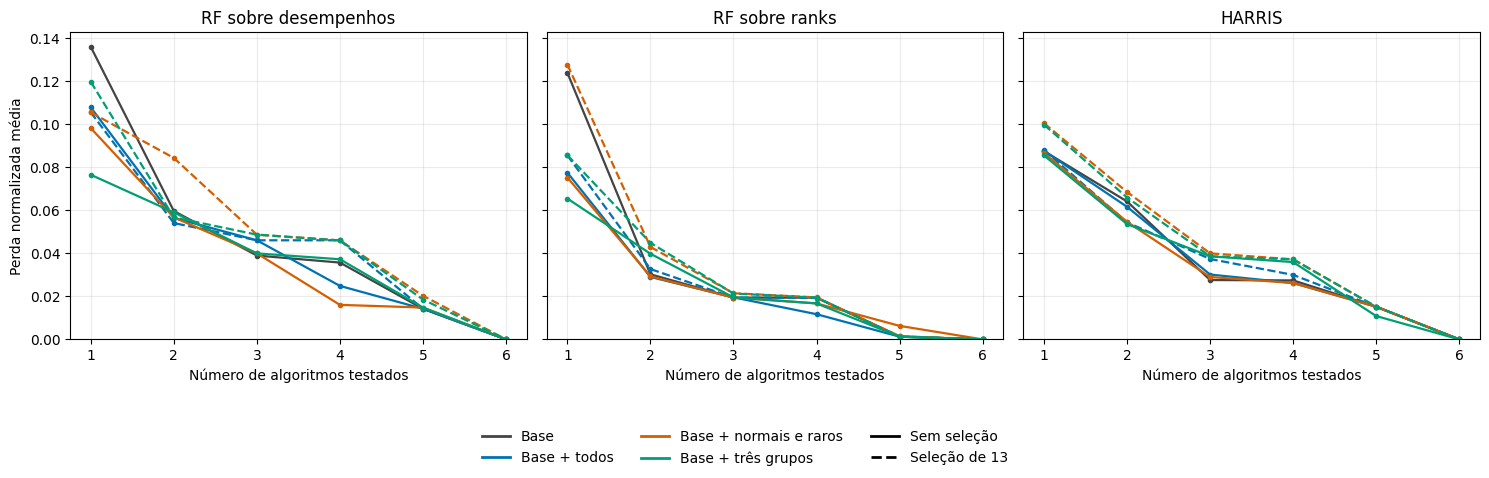

In [64]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

colunas_perda = [f"perda_t{i}" for i in range(1, 7)]

curvas = (
    resultados_finais
    .groupby(["representacao", "tratamento", "abordagem"])[
        colunas_perda
    ]
    .mean()
)

curvas.to_csv(pasta_final / "curvas_perda.csv")

cores = {
    "base": "#444444",
    "base_mais_todos": "#0072B2",
    "base_mais_normais_raros": "#D55E00",
    "base_mais_todos_normais_raros": "#009E73",
}

rotulos = {
    "base": "Base",
    "base_mais_todos": "Base + todos",
    "base_mais_normais_raros": "Base + normais e raros",
    "base_mais_todos_normais_raros": "Base + três grupos",
}

abordagens = {
    "Abordagem_1": "RF sobre desempenhos",
    "Abordagem_2": "RF sobre ranks",
    "HARRIS": "HARRIS",
}

t = np.arange(1, 7)

fig, eixos = plt.subplots(
    1, 3,
    figsize=(15, 4.8),
    sharex=True,
    sharey=True,
)

for eixo, (abordagem, titulo) in zip(
    eixos, abordagens.items()
):
    for representacao, cor in cores.items():
        for tratamento, estilo in [
            ("sem_selecao", "-"),
            ("selecao_13", "--"),
        ]:
            # A base é idêntica nos dois tratamentos:
            # desenhamos apenas uma vez.
            if (
                representacao == "base"
                and tratamento == "selecao_13"
            ):
                continue

            perdas = curvas.loc[
                (representacao, tratamento, abordagem),
                colunas_perda,
            ].to_numpy(dtype=float)

            eixo.plot(
                t,
                perdas,
                color=cor,
                linestyle=estilo,
                marker="o",
                markersize=3,
                linewidth=1.6,
            )

    eixo.set_title(titulo)
    eixo.set_xlabel("Número de algoritmos testados")
    eixo.set_xticks(t)
    eixo.set_ylim(bottom=0)
    eixo.grid(alpha=0.25)

eixos[0].set_ylabel("Perda normalizada média")

legenda = [
    Line2D([0], [0], color=cor, lw=2, label=rotulos[nome])
    for nome, cor in cores.items()
]

legenda += [
    Line2D(
        [0], [0], color="black", lw=2,
        linestyle="-", label="Sem seleção",
    ),
    Line2D(
        [0], [0], color="black", lw=2,
        linestyle="--", label="Seleção de 13",
    ),
]

fig.legend(
    handles=legenda,
    loc="lower center",
    ncol=3,
    frameon=False,
)

fig.tight_layout(rect=[0, 0.16, 1, 1])

PASTA_FIGURAS.mkdir(parents=True, exist_ok=True)

fig.savefig(
    PASTA_FIGURAS / "curvas_perda_representacoes.pdf",
    bbox_inches="tight",
)
fig.savefig(
    PASTA_FIGURAS / "curvas_perda_representacoes.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()

## 22. Teste estatístico

Teste de Friedman em cada abordagem, com nível 0,05/3, e Nemenyi para o diagrama de diferença crítica.

In [ ]:
from itertools import combinations
from scipy.stats import friedmanchisquare, studentized_range

CONFIGURACOES = [
    ("base", "sem_selecao", "Base"),
    ("base_mais_todos", "sem_selecao", "Todos"),
    ("base_mais_normais_raros", "sem_selecao", "Normais + raros"),
    ("base_mais_todos_normais_raros", "sem_selecao", "Três grupos"),
    ("base_mais_todos", "selecao_13", "Todos / seleção"),
    ("base_mais_normais_raros", "selecao_13", "Normais + raros / seleção"),
    ("base_mais_todos_normais_raros", "selecao_13", "Três grupos / seleção"),
]

ABORDAGENS = {
    "Abordagem_1": "RF sobre desempenhos",
    "Abordagem_2": "RF sobre ranks",
    "HARRIS": "HARRIS",
}


def grupos_maximais(ranks, cd):
    # Intervalos de configurações em que todas as diferenças de rank ficam abaixo da CD.
    candidatos = [
        (i, j)
        for i in range(len(ranks))
        for j in range(i + 1, len(ranks))
        if ranks[j] - ranks[i] <= cd
    ]
    return [
        (i, j) for i, j in candidatos
        if not any(a <= i and j <= b and (a, b) != (i, j) for a, b in candidatos)
    ]


def desenhar_cd(ax, ranks, cd, titulo, p, alpha):
    ranks = ranks.sort_values(kind="stable")
    k = len(ranks)

    ax.set_xlim(-2.6, k + 3.6)
    ax.set_ylim(-1.65, 1.1)
    ax.axis("off")
    ax.set_title(f"{titulo} — Friedman p={p:.4g}; α por abordagem={alpha:.4f}", fontsize=11)

    ax.plot([1, k], [0.5, 0.5], color="black", lw=1)
    for pos in range(1, k + 1):
        ax.plot([pos, pos], [0.46, 0.54], color="black", lw=1)
        ax.text(pos, 0.59, str(pos), ha="center", fontsize=9)

    ax.plot([1, 1 + cd], [0.9, 0.9], color="black", marker="|", markersize=8)
    ax.text(1 + cd / 2, 0.96, f"CD = {cd:.3f}", ha="center", fontsize=9)

    for i, (nome, rank) in enumerate(ranks.items()):
        if i < (k + 1) // 2:
            y = -0.55 - 0.25 * i
            ax.plot([rank, rank, 0.8], [0.5, y, y], color="0.65", lw=0.8)
            ax.text(0.7, y, f"{nome} ({rank:.2f})", ha="right", va="center", fontsize=9)
        else:
            y = -0.55 - 0.25 * (k - 1 - i)
            ax.plot([rank, rank, k + 0.2], [0.5, y, y], color="0.65", lw=0.8)
            ax.text(k + 0.3, y, f"({rank:.2f}) {nome}", ha="left", va="center", fontsize=9)

    for nivel, (i, j) in enumerate(grupos_maximais(ranks.to_numpy(), cd)):
        y = 0.32 - 0.12 * nivel
        ax.plot([ranks.iloc[i], ranks.iloc[j]], [y, y], color="black", lw=3)

    ax.text((k + 1) / 2, -1.5, "Menor rank médio = menor área de perda", ha="center", fontsize=9)


def comparar_representacoes(resultados, pasta, pasta_figuras, alpha_global=0.05):
    pasta, pasta_figuras = Path(pasta), Path(pasta_figuras)
    pasta.mkdir(parents=True, exist_ok=True)
    pasta_figuras.mkdir(parents=True, exist_ok=True)

    # Nemenyi dentro de cada abordagem e Bonferroni entre as três.
    alpha = alpha_global / len(ABORDAGENS)

    omnibus, pares, registros_ranks = [], [], []
    fig, eixos = plt.subplots(3, 1, figsize=(14, 10.5))

    for ax, (abordagem, titulo) in zip(eixos, ABORDAGENS.items()):
        series = []
        for representacao, tratamento, nome in CONFIGURACOES:
            bloco = resultados.loc[
                (resultados["abordagem"] == abordagem)
                & (resultados["representacao"] == representacao)
                & (resultados["tratamento"] == tratamento)
            ]
            series.append(bloco.set_index("dataset")["auc_perda"].rename(nome))

        matriz = pd.concat(series, axis=1).sort_index()
        matriz.to_csv(pasta / f"areas_pareadas_{abordagem}.csv")
        n, k = matriz.shape

        if (matriz.nunique(axis=1) == 1).all():
            estatistica, p = 0.0, 1.0
        else:
            estatistica, p = friedmanchisquare(*[matriz[c] for c in matriz])

        ranks = matriz.rank(axis=1, method="average", ascending=True).mean()
        erro_padrao = np.sqrt(k * (k + 1) / (6 * n))
        cd = float(studentized_range.ppf(1 - alpha, k, np.inf) / np.sqrt(2) * erro_padrao)

        omnibus.append({
            "abordagem": abordagem, "n_datasets": n, "k": k,
            "friedman": float(estatistica), "p_friedman": float(p),
            "p_friedman_bonferroni": min(1.0, p * 3),
            "alpha_por_abordagem": alpha, "CD": cd,
            "rejeita_friedman": p < alpha,
        })

        for nome in ranks.index:
            registros_ranks.append({
                "abordagem": abordagem, "configuracao": nome,
                "rank_medio_area": ranks[nome],
                "area_media": matriz[nome].mean(),
            })

        for a, b in combinations(ranks.index, 2):
            diferenca = abs(ranks[a] - ranks[b])
            p_nem = float(studentized_range.sf(np.sqrt(2) * diferenca / erro_padrao, k, np.inf))
            pares.append({
                "abordagem": abordagem, "configuracao_a": a, "configuracao_b": b,
                "diferenca_rank": diferenca, "p_nemenyi": p_nem,
                "p_nemenyi_bonferroni": min(1.0, 3 * p_nem),
                # Um par só conta como diferente se Friedman também rejeitar.
                "significativo": bool(p < alpha and diferenca > cd),
            })

        desenhar_cd(ax, ranks, cd, titulo, p, alpha)

    fig.suptitle("Diferença crítica — área da curva de perda", fontsize=14)
    fig.text(
        0.5, 0.012,
        "Barras: grupos sem diferença detectada por Nemenyi; não demonstram equivalência.\n"
        "Conclusões por pares exigem também rejeição de Friedman. α global = 0,05; três abordagens.",
        ha="center", fontsize=9,
    )
    fig.tight_layout(rect=[0, 0.055, 1, 0.97])
    fig.savefig(pasta_figuras / "diferenca_critica_area.pdf", bbox_inches="tight")
    fig.savefig(pasta_figuras / "diferenca_critica_area.png", dpi=200, bbox_inches="tight")

    omnibus, pares, registros_ranks = map(pd.DataFrame, (omnibus, pares, registros_ranks))
    omnibus.to_csv(pasta / "friedman_area.csv", index=False)
    pares.to_csv(pasta / "nemenyi_area.csv", index=False)
    registros_ranks.to_csv(pasta / "ranks_medios_area.csv", index=False)

    return omnibus, pares, registros_ranks, fig

Comparação global:


,abordagem,n_datasets,k,friedman,p_friedman,p_friedman_bonferroni,alpha_por_abordagem,CD,rejeita_friedman
0,Abordagem_1,30,7,10.353546,0.110531,0.331594,0.016667,1.842008,False
1,Abordagem_2,30,7,8.040000,0.235187,0.705562,0.016667,1.842008,False
2,HARRIS,30,7,5.752747,0.451450,1.000000,0.016667,1.842008,False



Comparações significativas após os controles:
Nenhum par apresentou diferença significativa.

Ranks médios da área de perda:


,abordagem,configuracao,rank_medio_area,area_media
2,Abordagem_1,Normais + raros,3.5667,0.0376
3,Abordagem_1,Três grupos,3.6333,0.0380
4,Abordagem_1,Todos / seleção,3.7667,0.0444
6,Abordagem_1,Três grupos / seleção,3.9167,0.0483
1,Abordagem_1,Todos,4.1167,0.0416
5,Abordagem_1,Normais + raros / seleção,4.3667,0.0508
0,Abordagem_1,Base,4.6333,0.0475
10,Abordagem_2,Três grupos,3.6167,0.0238
8,Abordagem_2,Todos,3.7833,0.0232
9,Abordagem_2,Normais + raros,3.9000,0.0245


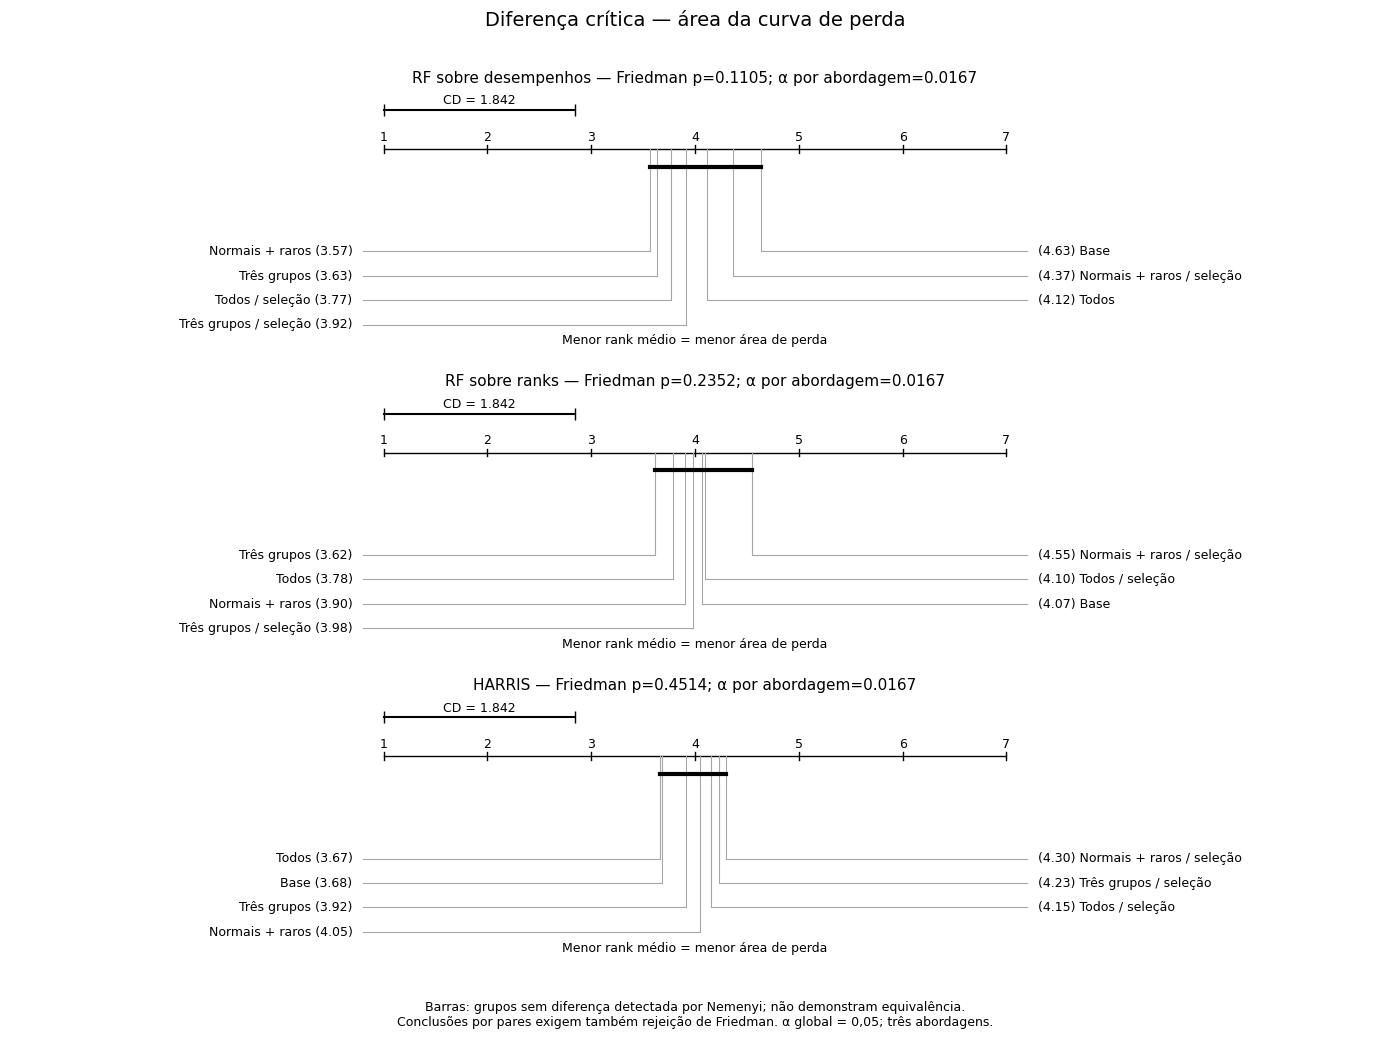

In [71]:
resultados_finais = pd.read_csv(
  PASTA_RESULTADOS / "avaliacao_final" / "resultados_por_dataset.csv"
)

testes_friedman, comparacoes_pares, ranks_area, figura_cd = (
  comparar_representacoes(
      resultados=resultados_finais,
      pasta=PASTA_RESULTADOS / "avaliacao_final",
      pasta_figuras=PASTA_FIGURAS,
  )
)

print("Comparação global:")
display(testes_friedman.round(6))

print("\nComparações significativas após os controles:")
significativas = comparacoes_pares.loc[comparacoes_pares["significativo"]]
if significativas.empty:
  print("Nenhum par apresentou diferença significativa.")
else:
  display(significativas.round(6))

print("\nRanks médios da área de perda:")
display(ranks_area.sort_values(["abordagem", "rank_medio_area"]).round(4))

plt.show()

## Resultado

O teste de Friedman não encontrou diferença significativa em nenhuma abordagem (p = 0,11, 0,24 e 0,45). As melhoras que aparecem nas médias não se sustentam no teste.